# Spotify Hit Prediction 

* Using spotify tracks data from 2010-2019s
* Dataset from Kaggle - https://www.kaggle.com/theoverman/the-spotify-hit-predictor-dataset
* There are 19 variables in the dataset
* Using the many attributes of a song, I trained an appropriate model to predict if a given song's attributes can tell us if that song is going to be a hit or not (1 or 0)


Since this is clearly a classification task, we just get to know the False Positives (FP) and False Negatives (FN) <br>
* FP - a song, which is a flop, is falsely predicted as a hit. The company or artist might lose money promoting that song,which is not loved (seen as a hit) by the general people according to the past data (not a hit).
* FN - a song, which is a hit, is falsely predicted as a flop. If the artist sees that their song is (falsely) going to be a flop, they might not release it at all, and the world may lose a hit, and the artist might lose some good money and recognition

In [1]:
import pandas as pd # for data manipulation
import numpy as np # for numerical computations
 
# for data visualization - matplotlib, seaborn, plotly
import matplotlib.pyplot as plt
import seaborn as sns 
import chart_studio.plotly as py
import plotly.io as pio
import plotly.graph_objects as go
import plotly.express as px
import cufflinks as cf

# ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
pd.options.plotting.backend = "plotly" # Plotly Express-powered backend for Pandas plotting. 

In [3]:
# setting defaults for matplotlib
plt.style.use("seaborn-whitegrid")
plt.rcParams["figure.figsize"] = (20,8)

In [4]:
# Read data
data = pd.read_csv('spotifyHitPredicto2010-2019.csv')

In [5]:
data.head() # first 5 rows of data

,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,target
0,Wild Things,Alessia Cara,spotify:track:2ZyuwVvV6Z3XJaXIFbspeE,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000,0.0828,0.706,108.029,188493,4,41.18681,10,1
1,Surfboard,Esquivel!,spotify:track:61APOtq25SCMuK0V5w2Kgp,0.447,0.247,5,-14.661,0,0.0346,0.87100,0.814,0.0946,0.250,155.489,176880,3,33.18083,9,0
2,Love Someone,Lukas Graham,spotify:track:2JqnpexlO9dmvjUMCaLCLJ,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000,0.1080,0.274,172.065,205463,4,44.89147,9,1
3,Music To My Ears (feat. Tory Lanez),Keys N Krates,spotify:track:0cjfLhk8WJ3etPTCseKXtk,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000,0.2040,0.291,91.837,193043,4,29.52521,7,0
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,spotify:track:1lItf5ZXJc1by9SbPeljFd,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000,0.3910,0.780,160.517,144244,4,24.99199,8,1


A brief understanding of the features: <br>
* track - name of the song
* artist - name of the artist
* uri - The unique resource identifier for the track
* danceability-describes how suitable a track is for dancing based on a combination of musical elements including tempo, rhythm stability, beat strength, and overall regularity
* energy - is a measure from 0.0 to 1.0 and represents a perceptual measure of intensity and activity. Typically, energetic tracks feel fast, loud, and noisy. 
* key-The estimated overall key of the track.If no key was detected, the value is -1.
* loudness- The overall loudness of a track in decibels (dB).Values typical range between -60 and 0 db. 
* mode - Mode indicates the modality (major or minor) of a track, the type of scale from which its melodic content is derived.
* speechiness - Speechiness detects the presence of spoken words in a track.
* acousticness - A confidence measure from 0.0 to 1.0 of whether the track is acoustic.
* instrumentalness - Predicts whether a track contains no vocals.
* liveness - Detects the presence of an audience in the recording. 
* valence -  the musical positiveness conveyed by a track.
* tempo - the speed or pace of a given piece and derives directly from the average beat duration. 
* duration_ms -  The duration of the track in milliseconds.
* time_signature - a notational convention to specify how many beats are in each bar (or measure).
* chorus_hit - The author's best estimate of when the chorus would start for the track. 
* sections - The number of sections the particular track has.
* target - The target variable can be either '0' or '1'. '1' implies that this song has featured in the weekly list (Issued by Billboards) of Hot-100 tracks in that decade at least once and is therefore a 'hit'. '0' Implies that the track is a 'flop'.

In [6]:
data.shape

(6398, 19)

In [8]:
## checking if the data classes are imbalanced or not
data['target'].value_counts()

0    3199
1    3199
Name: target, dtype: int64

<img width='500px' src="https://i.kym-cdn.com/entries/icons/original/000/027/257/perfectly-balanced-as-all-things-should-be.jpg" />

## Data Cleaning

In [9]:
data=data.rename(columns={'target':'hit'}) # renaming the target column as hit (1, if it is a hit, 0 if the track isn't a hit)

In [10]:
data.head()

,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit
0,Wild Things,Alessia Cara,spotify:track:2ZyuwVvV6Z3XJaXIFbspeE,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000,0.0828,0.706,108.029,188493,4,41.18681,10,1
1,Surfboard,Esquivel!,spotify:track:61APOtq25SCMuK0V5w2Kgp,0.447,0.247,5,-14.661,0,0.0346,0.87100,0.814,0.0946,0.250,155.489,176880,3,33.18083,9,0
2,Love Someone,Lukas Graham,spotify:track:2JqnpexlO9dmvjUMCaLCLJ,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000,0.1080,0.274,172.065,205463,4,44.89147,9,1
3,Music To My Ears (feat. Tory Lanez),Keys N Krates,spotify:track:0cjfLhk8WJ3etPTCseKXtk,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000,0.2040,0.291,91.837,193043,4,29.52521,7,0
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,spotify:track:1lItf5ZXJc1by9SbPeljFd,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000,0.3910,0.780,160.517,144244,4,24.99199,8,1


In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6398 entries, 0 to 6397
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track             6398 non-null   object 
 1   artist            6398 non-null   object 
 2   uri               6398 non-null   object 
 3   danceability      6398 non-null   float64
 4   energy            6398 non-null   float64
 5   key               6398 non-null   int64  
 6   loudness          6398 non-null   float64
 7   mode              6398 non-null   int64  
 8   speechiness       6398 non-null   float64
 9   acousticness      6398 non-null   float64
 10  instrumentalness  6398 non-null   float64
 11  liveness          6398 non-null   float64
 12  valence           6398 non-null   float64
 13  tempo             6398 non-null   float64
 14  duration_ms       6398 non-null   int64  
 15  time_signature    6398 non-null   int64  
 16  chorus_hit        6398 non-null   float64


In [12]:
# check to see if there are any null values
data.isna().sum()

track               0
artist              0
uri                 0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
duration_ms         0
time_signature      0
chorus_hit          0
sections            0
hit                 0
dtype: int64

Thus, it is clear that there are no null values in any of the features

In [13]:
data.describe() # different statistics regarding the numerical features

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit
count,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6398.000000,6.398000e+03,6398.000000,6398.000000,6398.000000,6398.000000
mean,0.568163,0.667756,5.283526,-7.589796,0.645514,0.098018,0.216928,0.165293,0.196700,0.443734,122.353871,2.367042e+05,3.930916,41.028399,10.316505,0.500000
std,0.191103,0.240721,3.606216,5.234592,0.478395,0.097224,0.296835,0.318736,0.166148,0.245776,29.847389,8.563698e+04,0.377469,19.568827,3.776011,0.500039
min,0.062200,0.000251,0.000000,-46.655000,0.000000,0.022500,0.000000,0.000000,0.016700,0.000000,39.369000,2.985300e+04,0.000000,0.000000,2.000000,0.000000
25%,0.447000,0.533000,2.000000,-8.425000,0.000000,0.038825,0.008533,0.000000,0.096800,0.240000,98.091250,1.932068e+05,4.000000,28.059135,8.000000,0.000000
50%,0.588000,0.712500,5.000000,-6.096500,1.000000,0.057200,0.067050,0.000017,0.126000,0.434000,121.070000,2.212465e+05,4.000000,36.265365,10.000000,0.500000
75%,0.710000,0.857000,8.000000,-4.601250,1.000000,0.112000,0.311000,0.057650,0.249000,0.628000,141.085000,2.593165e+05,4.000000,48.292538,12.000000,1.000000
max,0.981000,0.999000,11.000000,-0.149000,1.000000,0.956000,0.996000,0.995000,0.982000,0.976000,210.977000,1.734201e+06,5.000000,213.154990,88.000000,1.000000


From the above information, we get the idea that the features are having different scales (for instance, if you look at the mean, you can see that the means for the features vary a lot)

In [14]:
# checking for any duplicates (based on all columns)
# Selecting duplicate rows except first occurrence based on all columns

duplicate_data = data[data.duplicated()]
duplicate_data  

,track,artist,uri,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit


No duplicate rows found as of now

## Boxplot of features

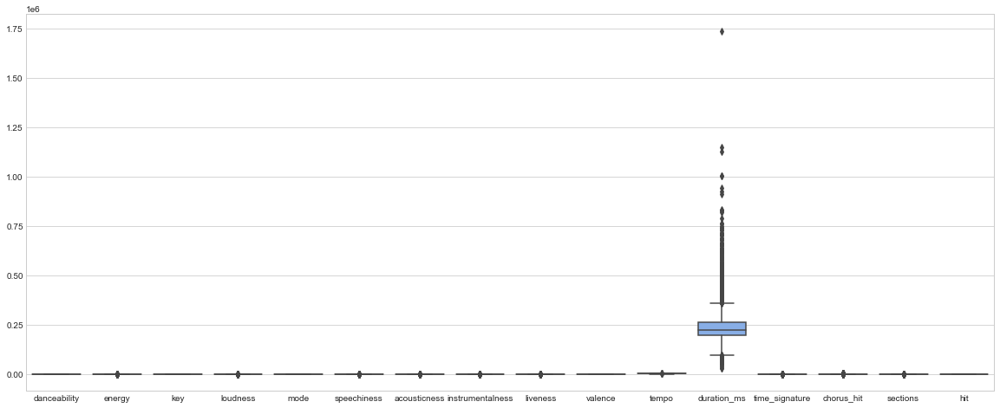

In [15]:
sns.boxplot(data=data)
plt.show()

duration_ms is in a different  scale than the others

The above plot is enough to tell us that the features have very different scales. As duration_ms have a larger scale of values, they squished other boxplots into a line. 

In [16]:
# numerical features in a list (all of the features not having a dtype of object)
num_features = [feature for feature in data.columns if data[feature].dtype!="O"]
print(num_features)
len(num_features)

['danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'time_signature', 'chorus_hit', 'sections', 'hit']


16

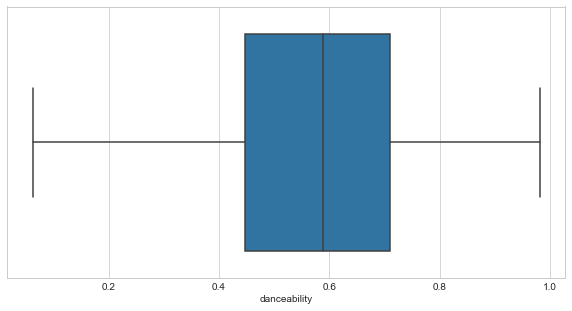

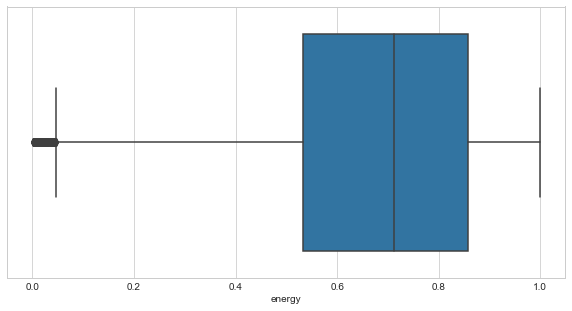

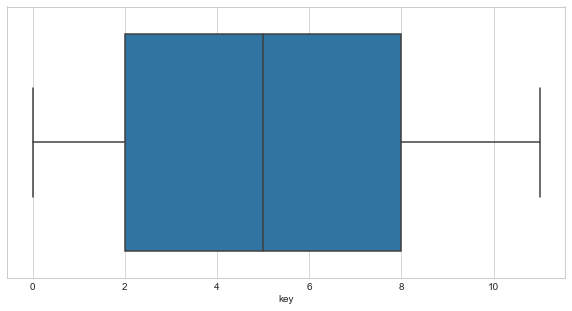

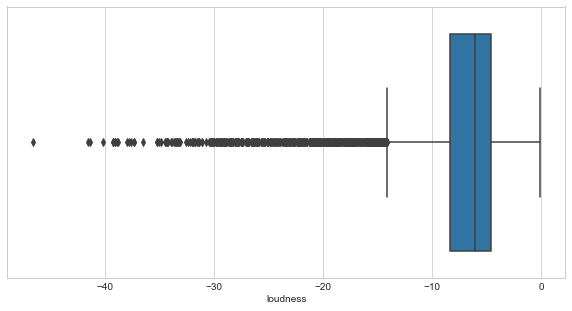

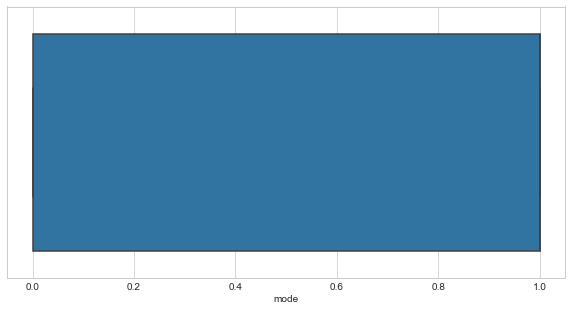

...

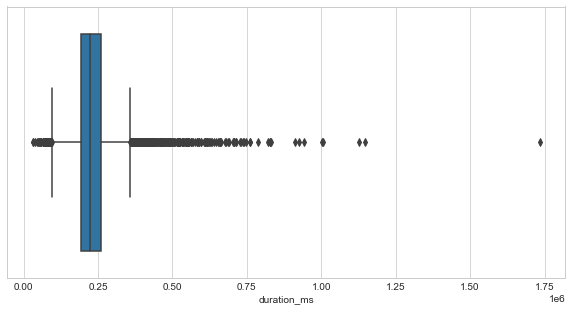

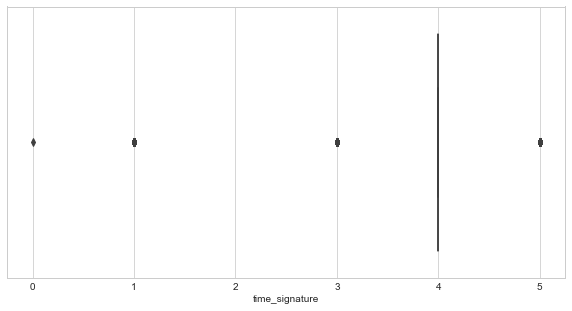

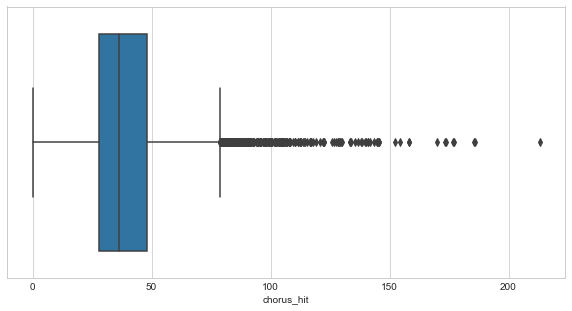

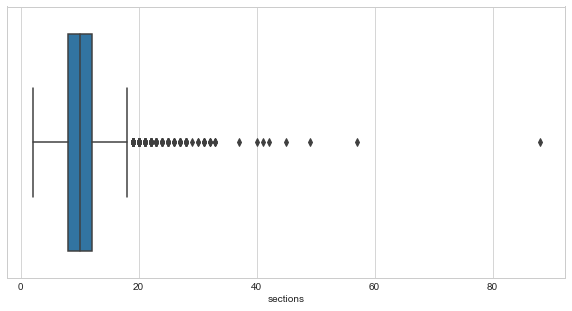

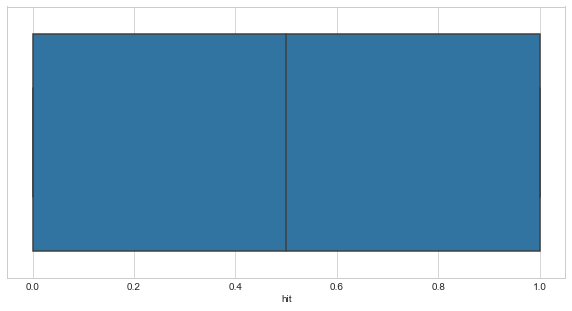

In [17]:
# Boxplots of numerical features , separately to get a better look
for col in num_features:
    #if data[col].values 
    fig= plt.subplots(1,figsize=(10,5))                
    plt_=sns.boxplot(x=data[col])

There are features with both discrete and continuous values here.<br>There are certainly some outliers, but these might contain valuable information as in the list of tracks, we have all sorts of tracks (speech, instruments, etc., according to the data documentation in kaggle) which might have different properties. So, I decided to keep them as they are.

In [18]:
## new column- duration in minutes (for interpretability and analysis)

data['duration_min']=(data.duration_ms/1000)/60

In [19]:
data[['duration_min','duration_ms']]

,duration_min,duration_ms
0,3.141550,188493
1,2.948000,176880
2,3.424383,205463
3,3.217383,193043
4,2.404067,144244
...,...,...
6393,2.514283,150857
6394,2.533333,152000
6395,3.796000,227760
6396,3.556450,213387


Removing `uri` feature as it is only an identifier 

In [20]:
# remove uri 
data = data.drop(['uri'],axis=1)
data.head()

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min
0,Wild Things,Alessia Cara,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000,0.0828,0.706,108.029,188493,4,41.18681,10,1,3.141550
1,Surfboard,Esquivel!,0.447,0.247,5,-14.661,0,0.0346,0.87100,0.814,0.0946,0.250,155.489,176880,3,33.18083,9,0,2.948000
2,Love Someone,Lukas Graham,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000,0.1080,0.274,172.065,205463,4,44.89147,9,1,3.424383
3,Music To My Ears (feat. Tory Lanez),Keys N Krates,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000,0.2040,0.291,91.837,193043,4,29.52521,7,0,3.217383
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000,0.3910,0.780,160.517,144244,4,24.99199,8,1,2.404067


After removing `uri`, checking for duplicates

In [21]:
# checking for duplicates based on all columns
# Selecting duplicate rows except first occurrence based on all columns

duplicate_data = data[data.duplicated()]
duplicate_data  

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min
845,Let Us Fly,Love Sees No Color,0.487,0.915,7,-5.413,1,0.0331,0.000278,0.000014,0.3720,0.5480,93.966,206005,4,21.52767,10,0,3.433417
951,Chebika - Claudio Mate Metal Remix,Stefano Patarnello,0.624,0.863,7,-8.142,0,0.0300,0.000004,0.945000,0.0849,0.0394,119.993,386000,4,58.49512,12,0,6.433333
1224,Metal Gods - Live from Battle Cry,Judas Priest,0.378,0.891,10,-4.735,1,0.0428,0.000010,0.013600,0.7770,0.1400,96.105,253867,4,48.45906,11,0,4.231117
1230,Cheap Thrills,Freedom Dub,0.754,0.615,6,-8.746,0,0.0461,0.030400,0.005780,0.1790,0.6200,90.005,216422,4,23.68503,9,0,3.607033
1286,"Le Bien, Le Mal",Guru,0.842,0.821,1,-9.860,1,0.1630,0.041300,0.002490,0.3460,0.5940,101.986,202160,4,20.45929,12,0,3.369333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6136,Falling,Julee Cruise,0.192,0.138,5,-17.135,1,0.0315,0.892000,0.553000,0.1140,0.0757,142.187,321853,4,60.94077,17,0,5.364217
6138,La Voix Du Corps - Deep Beats Mix,Area 42,0.890,0.641,1,-10.766,1,0.1410,0.130000,0.001360,0.0714,0.4420,119.961,213500,4,30.50348,9,0,3.558333
6295,Hey Deannie,Mcrackins,0.300,0.985,7,-3.161,1,0.1120,0.008840,0.000000,0.0788,0.5300,171.613,164160,4,33.32510,10,0,2.736000
6312,A Heap of Broken Images,Hord,0.252,0.975,4,-3.809,0,0.2110,0.000074,0.001330,0.3210,0.0683,148.658,328507,4,26.73991,12,0,5.475117


After removing `uri`, which is a unique resource identifier from Spotify for songs, we can see that there are now duplicate songs, which had all other columns ,except the `uri` column, with the exact same values. <br> As we are not passing in the `uri` column to our models, since it is just an identifier, we need to make sure that we are not feeding the model duplicate data.

In [22]:
duplicate_data[duplicate_data['hit']==1] # no duplicate hits. Only flops

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min


If the duplicates belong to only one class, then it may introduce bias in your classification, as the model sees them a lot. 

For instance, lets take all instances in the data for `Cheap Thrills by Freedom Dub` to see if the values of all the variables are the same for all of its instances

In [23]:
data[(data['artist']=="Freedom Dub") & (data['track']=="Cheap Thrills")]

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min
1199,Cheap Thrills,Freedom Dub,0.754,0.615,6,-8.746,0,0.0461,0.0304,0.00578,0.179,0.62,90.005,216422,4,23.68503,9,0,3.607033
1230,Cheap Thrills,Freedom Dub,0.754,0.615,6,-8.746,0,0.0461,0.0304,0.00578,0.179,0.62,90.005,216422,4,23.68503,9,0,3.607033


It is clear that the values for all variables are the same, for the two rows

In [24]:
6398-110 # After removing the duplicated rows of count 110 from the total number of rows (6398), we should get 6288 rows

6288

Values for each column are the same. So, it makes sense to remove these duplicates

In [25]:
# removing the duplicates
combined = data.append(duplicate_data)
data=combined[~combined.index.duplicated(keep=False)]

In [26]:
data.shape

(6288, 19)

Checking that ,now, there is only one occurence of `Cheap Thrills by Freedom Dub`

In [27]:
data[(data['artist']=="Freedom Dub") & (data['track']=="Cheap Thrills")] # only one occurence

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min
1199,Cheap Thrills,Freedom Dub,0.754,0.615,6,-8.746,0,0.0461,0.0304,0.00578,0.179,0.62,90.005,216422,4,23.68503,9,0,3.607033


## Exploratory Data Analysis

<AxesSubplot:>

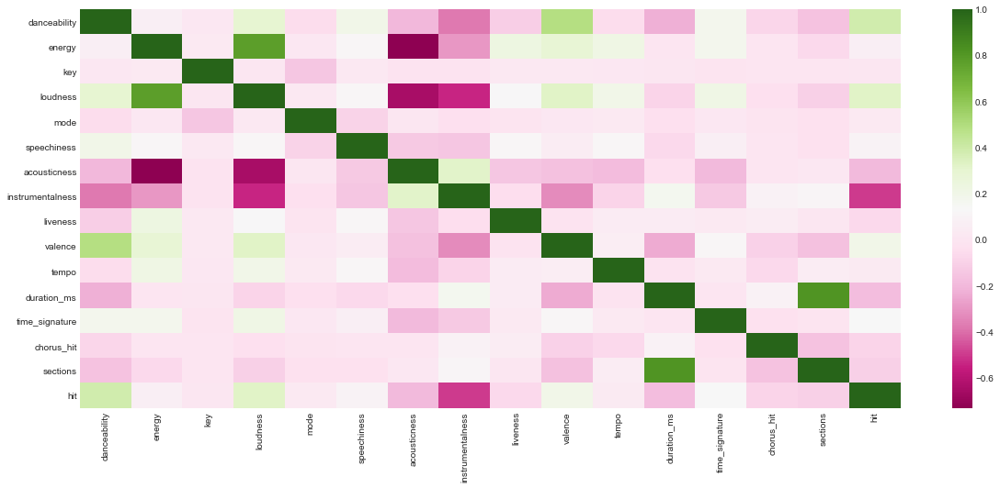

In [28]:
sns.heatmap(data.drop(columns=['duration_min']).corr(),cmap="PiYG")

Features highly correlated with 'hit': 
* hit and __duration__ are negatively correlated, strength = medium
* hit and __valence__ are positively correlated , strength = low
* hit and **instrumentalness** are negatively correlated, strength = high
* hit and __acousticness__ are negatively correlated , strength = medium
* hit and __loudness__ are positively correlated, strength = low to medium
* hit and __danceability__ are positively correlated, strength = low to medium (more than thaht of loudness)
* no corr with time_signature, speechiness(almost) 

### Getting a feel of the various features

(Mostly out of curiosity🧐)

__Key__

key: The estimated overall key of the track. Integers map to pitches using standard Pitch Class notation. E.g. 0 = C, 1 = C?/D?, 2 = D, and so on. If no key was detected, the value is -1

In [29]:
data.key.unique() # pitches from 1 to 11 

array([ 1,  5,  9,  0,  2,  7,  8, 11,  3,  4,  6, 10], dtype=int64)

In [30]:
data[data['key']== -1] # no tracks with the key undetected

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min


__Sections__

In [31]:
print(data.sections.min()) # minimum number of sections in a track
print(data.sections.max())# maximum number of sections in a track

2
88


Which track had 88 😶 sections?

In [32]:
data[data['sections']==88] 

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min
1430,Music for Sleep,Dr. Sounds,0.163,0.00547,9,-34.284,0,0.0532,0.99,0.915,0.166,0.0367,138.046,1734201,4,34.13513,88,0,28.90335


`Music for Sleep` ,which is not essentially a song,and had a duration of around 29 minutes ,is the track that had 88 sections.

__duration_min__

In [33]:
data['duration_min'].describe()

count    6288.000000
mean        3.931569
std         1.425832
min         0.497550
25%         3.215217
50%         3.678883
75%         4.300262
max        28.903350
Name: duration_min, dtype: float64

In [34]:
round(data.duration_min.max(),0) # 29 min is the max duration of a track in the dataset

29.0

In [35]:
# avg duration in minutes of hit songs
# subsetting the hit songs
hits = data[data['hit']==1]

In [36]:
hits.shape # 19, because of the new added column - duration_min and since 'uri' is removed

(3199, 19)

In [37]:
hits['duration_min'].describe()

count    3199.000000
mean        3.675044
std         0.727134
min         0.989783
25%         3.252083
50%         3.609550
75%         3.994550
max        11.474217
Name: duration_min, dtype: float64

In [38]:
round(hits.duration_min.max(),0)  # the max duration of a hit song is 11 min (in a dataset where the max duration is 29 min)

11.0

In [39]:
np.mean(hits['duration_min'])

3.6750444045014055

Thus, from above, the mean duration of a hit song in the 2010-2019s was just above 3 and a half minutes.

In [40]:
hits.describe() # avg values of hit songs

,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min
count,3199.000000,3199.000000,3199.000000,3199.000000,3199.000000,3199.000000,3199.000000,3199.000000,3199.000000,3199.000000,3199.000000,3199.000000,3199.000000,3199.000000,3199.000000,3199.0,3199.000000
mean,0.641633,0.682367,5.303532,-5.875753,0.660832,0.107524,0.162173,0.006057,0.186298,0.493813,123.524576,220502.664270,3.979056,39.353687,9.888403,1.0,3.675044
std,0.142438,0.166443,3.635618,2.203026,0.473501,0.106353,0.206048,0.051523,0.144925,0.216325,29.052186,43628.031893,0.266774,17.469300,2.464581,0.0,0.727134
min,0.201000,0.056100,0.000000,-23.023000,0.000000,0.022500,0.000025,0.000000,0.016700,0.035200,48.718000,59387.000000,1.000000,13.733290,3.000000,1.0,0.989783
25%,0.547000,0.573000,2.000000,-6.972000,0.000000,0.038300,0.020550,0.000000,0.097000,0.325000,99.967000,195125.000000,4.000000,27.890200,8.000000,1.0,3.252083
50%,0.645000,0.704000,6.000000,-5.567000,1.000000,0.058600,0.073600,0.000000,0.127000,0.487000,123.815000,216573.000000,4.000000,35.158990,10.000000,1.0,3.609550
75%,0.741000,0.809000,8.000000,-4.389000,1.000000,0.132500,0.221000,0.000011,0.231000,0.654500,142.673000,239673.000000,4.000000,46.203670,11.000000,1.0,3.994550
max,0.981000,0.991000,11.000000,-0.716000,1.000000,0.733000,0.992000,0.961000,0.979000,0.976000,208.067000,688453.000000,5.000000,213.154990,24.000000,1.0,11.474217


Using describe() on the hit subset, we can see the statistics of hit songs. <br>
* The mean danceability of a hit song is 0.64 with a standard deviation of 0.14 (where danceability ranges from 0 to 1, thus, hit songs do have a good danceability)
* The mean energy of a hit song is 0.68 with a standard deviation of 0.17 ( energy also varied from 0 to 1 and thus, hit songs again have a great deal of energy usually (above 0.5))
* Speechiness mean is low (0.11), with a std deviation of 0.11. Thus, hit songs might have lower speechiness values. (this may vary, as maybe speechiness might not affect the target as much)
* Acousticness has a mean of 0.16 with a std deviation of 0.2. <br>
Thus, we can find such statistics on all of the features, and get some idea on what are the properties of a hit song. But, note that there are some outliers in these variables, which might affect the mean and mess with the reliability of the mean

__danceability__

In [41]:
## most danceable songs (according to the description in the data (Kaggle) = 1) and if they were a hit or not
data[data['danceability']== 1.0] # no such songs

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min


So, lets see how many of the songs have a danceability of more than 0.5

In [42]:
data[data['danceability'] > 0.5]

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min
0,Wild Things,Alessia Cara,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000000,0.0828,0.706,108.029,188493,4,41.18681,10,1,3.141550
2,Love Someone,Lukas Graham,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000000,0.1080,0.274,172.065,205463,4,44.89147,9,1,3.424383
3,Music To My Ears (feat. Tory Lanez),Keys N Krates,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000000,0.2040,0.291,91.837,193043,4,29.52521,7,0,3.217383
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000000,0.3910,0.780,160.517,144244,4,24.99199,8,1,2.404067
6,Sex Metal Barbie,In This Moment,0.533,0.935,0,-3.704,1,0.1280,0.01390,0.000000,0.1680,0.481,140.092,262493,4,21.04510,14,0,4.374883
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6391,Sweater Weather,The Neighbourhood,0.612,0.807,10,-2.810,1,0.0336,0.04950,0.017700,0.1010,0.398,124.053,240400,4,91.20552,7,1,4.006667
6392,Untouchable,YoungBoy Never Broke Again,0.780,0.784,1,-5.039,1,0.1860,0.04470,0.000000,0.1220,0.430,85.023,180706,4,46.62277,8,1,3.011767
6394,Calling My Spirit,Kodak Black,0.910,0.366,1,-9.954,1,0.0941,0.09960,0.000000,0.2610,0.740,119.985,152000,4,32.53856,8,1,2.533333
6395,Teenage Dream,Katy Perry,0.719,0.804,10,-4.581,1,0.0355,0.01320,0.000003,0.1390,0.605,119.999,227760,4,20.73371,7,1,3.796000


Around 4219 tracks, out of 6288, have a danceability above 0.5. <br> To see how many of this were hits

In [43]:
hits[hits['danceability'] > 0.5]

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min
0,Wild Things,Alessia Cara,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000000,0.0828,0.706,108.029,188493,4,41.18681,10,1,3.141550
2,Love Someone,Lukas Graham,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000000,0.1080,0.274,172.065,205463,4,44.89147,9,1,3.424383
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000000,0.3910,0.780,160.517,144244,4,24.99199,8,1,2.404067
7,Helluva Night,Ludacris,0.736,0.522,2,-8.020,1,0.1160,0.02990,0.000000,0.1080,0.369,97.547,200387,4,60.21027,10,1,3.339783
10,Break Up In The End,Cole Swindell,0.507,0.372,1,-8.433,1,0.0303,0.48100,0.000000,0.2710,0.257,86.422,199693,4,36.66287,10,1,3.328217
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6390,Tear In My Heart,twenty one pilots,0.655,0.632,2,-4.802,1,0.0489,0.01890,0.000000,0.0722,0.447,120.113,188493,4,51.52804,8,1,3.141550
6391,Sweater Weather,The Neighbourhood,0.612,0.807,10,-2.810,1,0.0336,0.04950,0.017700,0.1010,0.398,124.053,240400,4,91.20552,7,1,4.006667
6392,Untouchable,YoungBoy Never Broke Again,0.780,0.784,1,-5.039,1,0.1860,0.04470,0.000000,0.1220,0.430,85.023,180706,4,46.62277,8,1,3.011767
6394,Calling My Spirit,Kodak Black,0.910,0.366,1,-9.954,1,0.0941,0.09960,0.000000,0.2610,0.740,119.985,152000,4,32.53856,8,1,2.533333


2682 out of the 4278 tracks (more than half of 4219) that has a danceability above 0.5 are hits

In [44]:
# correlation between danceability and hit columns (without any subsets)
data[['danceability','hit']].corr()

,danceability,hit
danceability,1.000000,0.386662
hit,0.386662,1.000000


They are thus positively correlated, even though the strength of the correlation is not that strong

In [45]:
# creating binned values (new variable) for different bins of danceability values
data['dance_bins']=data.danceability.apply(lambda x: 'High' if x>=0.7 else('Medium' if (x>=0.4 and x<0.7) else 'Low'))

In [46]:
data[['dance_bins','danceability']]

,dance_bins,danceability
0,High,0.741
1,Medium,0.447
2,Medium,0.550
3,Medium,0.502
4,High,0.807
...,...,...
6393,Low,0.172
6394,High,0.910
6395,High,0.719
6396,Medium,0.600


In [47]:
 data['dance_bins'].value_counts().plot(kind='bar',template="ggplot2",
                                     labels=dict(index="levels",value="count", variable="danceability bins"))
# data['dance_bins'].value_counts().plot(kind='bar')

In [48]:
data['dance_bins'].value_counts()

Medium    3390
High      1695
Low       1203
Name: dance_bins, dtype: int64

In [49]:
pd.crosstab(data['dance_bins'],data['hit'])

hit,0,1
dance_bins,,
High,574,1121
Low,1040,163
Medium,1475,1915


In [50]:
fig = data.plot.bar(data['dance_bins'],facet_row="hit",color='dance_bins',template='none')
fig.show()

In terms of danceability, we can infer that:
* Most of the songs with __high__ danceability are __hits__
* Most of the songs with __low__ danceability are __flops__ and only 163 out of the total 1203 low danceability songs were hits
* Out of 3390 songs with medium (b/w 0.4 and 0.7) danceability, comparatively (by a small amount), 1915 songs were hits and 1475 were flops

_Having high danceability thus might help a track become a hit_

## Top 10 artists with high danceability and their respective songs

In [51]:
top_10_dance= data.sort_values(by=['danceability'],ascending=False).head(10)
fig = px.bar(top_10_dance, x="artist", y="danceability", 
                title="Top 10 high danceability artists and their respective tracks",text='track',
             color="danceability",color_continuous_scale="emrld")
fig.show()

#### Valence

In [52]:
# how valence correlates with other features 
valence_corr = data[['valence','hit','danceability','energy','instrumentalness','loudness']].corr()
valence_corr

,valence,hit,danceability,energy,instrumentalness,loudness
valence,1.000000,0.199458,0.492436,0.282960,-0.331186,0.324446
hit,0.199458,1.000000,0.386662,0.064461,-0.500596,0.328659
danceability,0.492436,0.386662,1.000000,0.065462,-0.374657,0.302552
energy,0.282960,0.064461,0.065462,1.000000,-0.293676,0.774028
instrumentalness,-0.331186,-0.500596,-0.374657,-0.293676,1.000000,-0.537726
loudness,0.324446,0.328659,0.302552,0.774028,-0.537726,1.000000


`valence` is less strongly correlated with `hit`, and out of all the features, it is most correlated with `danceability `(positively) and is negatively correlated with `instrumentalness`

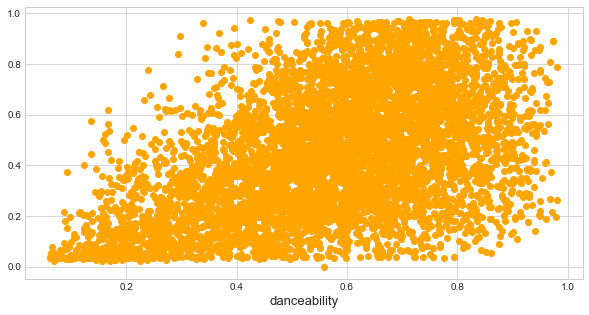

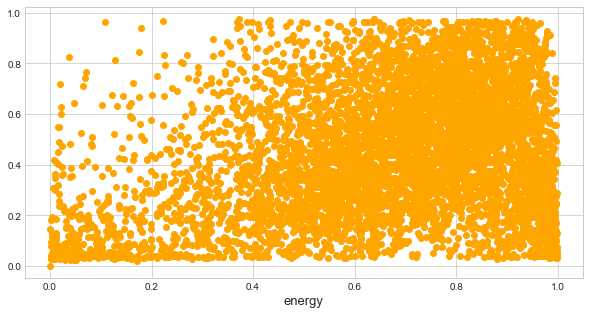

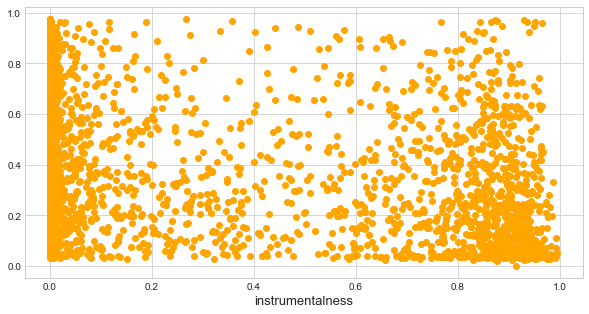

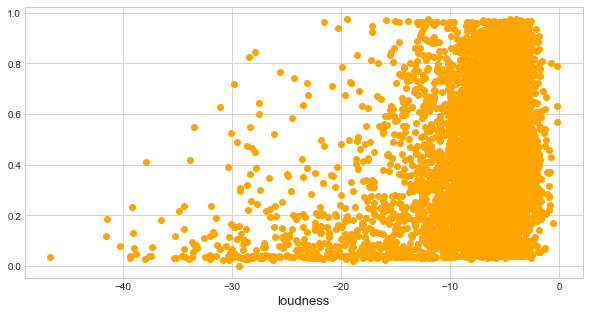

In [53]:
# Using scatter plots to visually see the relation of valence with other features
for feature in ['danceability','energy','instrumentalness','loudness']:
    plt.figure(figsize=(10,5))
    plt.scatter(data[feature],data['valence'],color='orange')
    plt.xlabel(feature,fontsize=13)
    plt.show()

In [54]:
data[list(data.columns)].corr()['valence'][:].sort_values(ascending=False) # with al features - discrete and continuous

valence             1.000000
danceability        0.492436
loudness            0.324446
energy              0.282960
hit                 0.199458
time_signature      0.118363
tempo               0.054161
speechiness         0.050445
key                 0.021881
mode                0.017063
liveness           -0.020592
chorus_hit         -0.102441
sections           -0.163659
acousticness       -0.163774
duration_min       -0.244757
duration_ms        -0.244757
instrumentalness   -0.331186
Name: valence, dtype: float64

Valence is more positively correlated with the danceability, loudness and energy of the track

In [55]:
# binning valence
hits[hits['valence']<0.5]

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min
2,Love Someone,Lukas Graham,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.0000,0.1080,0.274,172.065,205463,4,44.89147,9,1,3.424383
7,Helluva Night,Ludacris,0.736,0.522,2,-8.020,1,0.1160,0.02990,0.0000,0.1080,0.369,97.547,200387,4,60.21027,10,1,3.339783
9,My Last,Big Sean Featuring Chris Brown,0.387,0.773,8,-5.685,1,0.1700,0.09800,0.0000,0.2090,0.368,78.629,254120,4,23.30245,9,1,4.235333
10,Break Up In The End,Cole Swindell,0.507,0.372,1,-8.433,1,0.0303,0.48100,0.0000,0.2710,0.257,86.422,199693,4,36.66287,10,1,3.328217
13,Crawling Back To You,Daughtry,0.438,0.919,0,-2.910,0,0.0495,0.00674,0.0000,0.1580,0.195,151.026,225813,4,34.01444,8,1,3.763550
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6380,Dark Necessities,Red Hot Chili Peppers,0.700,0.742,5,-6.777,0,0.0716,0.07220,0.0199,0.1100,0.197,91.959,302000,4,20.40806,12,1,5.033333
6389,What Now,Rihanna,0.402,0.696,8,-4.799,0,0.0448,0.04760,0.0000,0.6280,0.227,180.158,243093,3,31.53643,11,1,4.051550
6390,Tear In My Heart,twenty one pilots,0.655,0.632,2,-4.802,1,0.0489,0.01890,0.0000,0.0722,0.447,120.113,188493,4,51.52804,8,1,3.141550
6391,Sweater Weather,The Neighbourhood,0.612,0.807,10,-2.810,1,0.0336,0.04950,0.0177,0.1010,0.398,124.053,240400,4,91.20552,7,1,4.006667


In [56]:
hits[hits['valence']>=0.5]

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min
0,Wild Things,Alessia Cara,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000000,0.0828,0.706,108.029,188493,4,41.18681,10,1,3.141550
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000000,0.3910,0.780,160.517,144244,4,24.99199,8,1,2.404067
5,Here's To Never Growing Up,Avril Lavigne,0.482,0.873,0,-3.145,1,0.0853,0.01110,0.000000,0.4090,0.737,165.084,214320,4,32.17301,12,1,3.572000
15,Hotline Bling,Drake,0.891,0.625,2,-7.861,1,0.0558,0.00261,0.000176,0.0504,0.548,134.967,267067,4,69.38968,8,1,4.451117
17,Beautiful People,Chris Brown Featuring Benny Benassi,0.417,0.806,5,-5.339,0,0.1600,0.07030,0.006370,0.0841,0.545,127.887,226773,4,14.73978,10,1,3.779550
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6385,Death,Trippie Redd Featuring DaBaby,0.802,0.820,10,-5.969,0,0.1460,0.05790,0.000000,0.1490,0.613,164.005,172196,4,17.21141,8,1,2.869933
6387,Kinfolks,Sam Hunt,0.565,0.805,0,-4.457,1,0.0489,0.08080,0.000000,0.1730,0.869,76.040,181933,4,38.94659,7,1,3.032217
6388,Strip That Down,Liam Payne Featuring Quavo,0.874,0.497,6,-5.484,1,0.0562,0.22000,0.000000,0.0761,0.542,106.023,204502,4,30.10821,10,1,3.408367
6394,Calling My Spirit,Kodak Black,0.910,0.366,1,-9.954,1,0.0941,0.09960,0.000000,0.2610,0.740,119.985,152000,4,32.53856,8,1,2.533333


Considering 0.5 as the division between high and low valence songs, among the hits,
* hit tracks with `valence` < 0.5 are more (1660)
* hit tracks with `valence` >= 0.5 are less (1539) <br> 
So , with 0.5 as the criteria, we see that the songs with low `valence` makes hits. But the difference between the low and high `valence` songs that make hits are not that big.

New binned variable to better understand `valence`

In [57]:
data['valence_bins']=data.valence.apply(lambda x: 'High' if x>=0.7 else('Medium' if (x>=0.4 and x<0.7) else 'Low'))

In [58]:
pd.crosstab(data['valence_bins'],data['hit'])

hit,0,1
valence_bins,,
High,508,634
Low,1699,1149
Medium,882,1416


With 3 classes , created by the above mentioned criteria, we see that songs that are positive do tend to make hits, but the difference between the highly positive and sad songs that make hits are not that big. So, valence might be spread out.That is,  high and low valence for a song might not affect it as much for it to be a hit. 

The two artists who had the maximum valence songs during 2010-2019 was Gene Autry and Austin Mahone ft Pitbull

### Top 5 valence song artist and songs

In [59]:
top_10_valence = data.sort_values(by=['valence'],ascending=False).head(10)
#plt.bar(top_5_valence['artist'],top_5_valence['valence'],label=top_5_valence['track'])
#plt.show()
fig = px.bar(top_10_valence, x="artist", y="valence", 
                title="Top 10 high valence artists and their respective tracks",text='track',
             color="valence",color_continuous_scale="geyser")
fig.show()
#fig = data.plot.bar(top_5_valence['artist'],top_5_valence['valence'],template='none',x="Artists",y="Valence")
#fig.show()

__energy__

In [60]:
# correlation of energy with other features
data[list(data.columns)].corr()['energy'][:].sort_values(ascending=False) 

energy              1.000000
loudness            0.774028
valence             0.282960
liveness            0.232541
tempo               0.220236
time_signature      0.180500
speechiness         0.116241
danceability        0.065462
hit                 0.064461
key                 0.027574
mode                0.012467
chorus_hit          0.001779
duration_min       -0.005870
duration_ms        -0.005870
sections           -0.065575
instrumentalness   -0.293676
acousticness       -0.731906
Name: energy, dtype: float64

`energy` has a very low correlation with `hit`

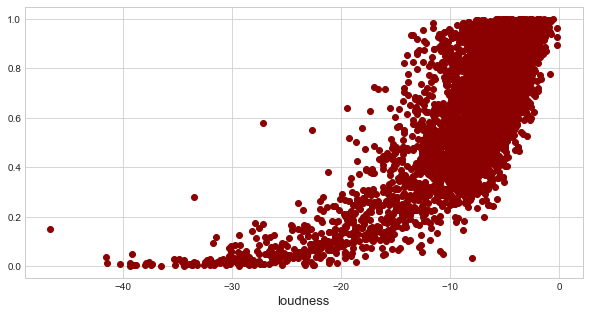

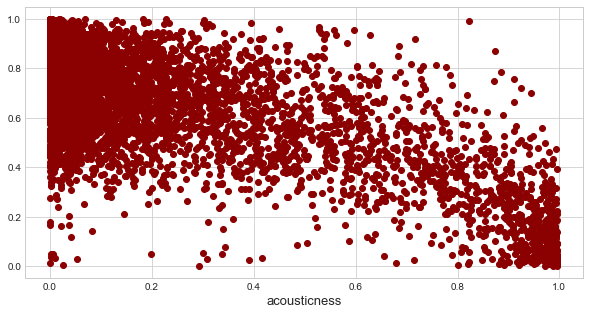

In [61]:
# Scatter plots
for feature in ['loudness','acousticness']:
    plt.figure(figsize=(10,5))
    plt.scatter(data[feature],data['energy'],color='darkred')
    plt.xlabel(feature,fontsize=13)
    plt.show()

`energy` is highly positively correlated with `loudness` and highly negatively correlated with `acousticness`, meaning that as `energy` increases, `loudness` increases and `acousticness` decreases

Energy is a measure from 0.0 to 1.0

In [62]:
data['energy_bins']=data.energy.apply(lambda x: 'High' if x>=0.7 else('Medium' if (x>=0.4 and x<0.7) else 'Low'))

In [63]:
pd.crosstab(data['energy_bins'],data['hit'])

hit,0,1
energy_bins,,
High,1626,1633
Low,665,192
Medium,798,1374


* Almost an equal amount of high energy songs are hits and flops
* Most of the low energy songs are flops
* More medium energy songs are hits

_So, it wouldn't hurt to have a fairly energetic song ,to be a hit_

### Top 10 tracks with high energy and their respective artists

In [64]:
top_10_energy = data.sort_values(by=['energy'],ascending=False).head(10)
fig = px.bar(top_10_energy, x="track", y="energy", 
                title="Top 10 high energy songs and their respective artists",text='artist',
             color="energy",color_continuous_scale="solar")
fig.show()

__Loudness__

Values typical range between -60 and 0 db. 

In [65]:
# correlation of loudness with other features
data[list(data.columns)].corr()['loudness'][:].sort_values(ascending=False) 

loudness            1.000000
energy              0.774028
hit                 0.328659
valence             0.324446
danceability        0.302552
time_signature      0.211662
tempo               0.195719
liveness            0.126083
speechiness         0.119043
mode                0.025111
key                 0.010650
chorus_hit         -0.038681
duration_min       -0.088906
duration_ms        -0.088906
sections           -0.104170
instrumentalness   -0.537726
acousticness       -0.647950
Name: loudness, dtype: float64

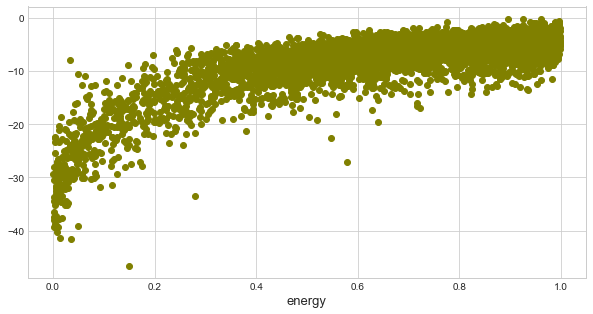

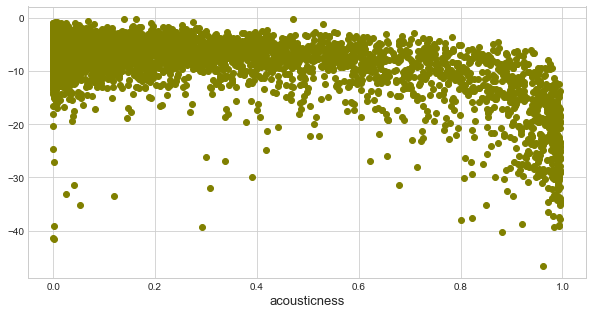

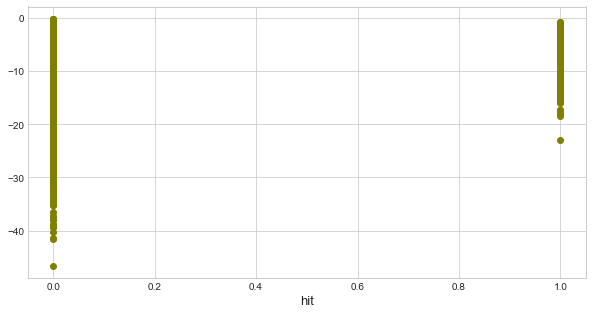

In [66]:
# Scatter plots
for feature in ['energy','acousticness','hit']:
    plt.figure(figsize=(10,5))
    plt.scatter(data[feature],data['loudness'],color='olive')
    plt.xlabel(feature,fontsize=13)
    plt.show()

We saw earlier that `loudness` is positively correlated with `energy`, and thus, is negatively correlated with `acousticness`. `loudness` is also fairly positively correlated with `hit`

In [67]:
-46>-40

False

In [68]:
# Song with the lowest value of loudness
data['hit'][data['loudness']==-46.655000] 
# not a hit

3274    0
Name: hit, dtype: int64

In [69]:
data[data['loudness']>-30]# since loudness ranges from 0 to -60. (taking its half as the division)

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,...,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min,dance_bins,valence_bins,energy_bins
0,Wild Things,Alessia Cara,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000000,...,108.029,188493,4,41.18681,10,1,3.141550,High,High,Medium
1,Surfboard,Esquivel!,0.447,0.247,5,-14.661,0,0.0346,0.87100,0.814000,...,155.489,176880,3,33.18083,9,0,2.948000,Medium,Low,Low
2,Love Someone,Lukas Graham,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000000,...,172.065,205463,4,44.89147,9,1,3.424383,Medium,Low,Medium
3,Music To My Ears (feat. Tory Lanez),Keys N Krates,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000000,...,91.837,193043,4,29.52521,7,0,3.217383,Medium,Low,Medium
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000000,...,160.517,144244,4,24.99199,8,1,2.404067,High,High,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6393,Lotus Flowers,Yolta,0.172,0.358,9,-14.430,1,0.0342,0.88600,0.966000,...,72.272,150857,4,24.30824,7,0,2.514283,Low,Low,Low
6394,Calling My Spirit,Kodak Black,0.910,0.366,1,-9.954,1,0.0941,0.09960,0.000000,...,119.985,152000,4,32.53856,8,1,2.533333,High,High,Low
6395,Teenage Dream,Katy Perry,0.719,0.804,10,-4.581,1,0.0355,0.01320,0.000003,...,119.999,227760,4,20.73371,7,1,3.796000,High,Medium,High
6396,Stormy Weather,Oscar Peterson,0.600,0.177,7,-16.070,1,0.0561,0.98900,0.868000,...,120.030,213387,4,21.65301,14,0,3.556450,Medium,Medium,Low


In [70]:
hits[hits['loudness']>-30] # since loudness ranges from 0 to -60. (taking its half as the division)

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min
0,Wild Things,Alessia Cara,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000000,0.0828,0.706,108.029,188493,4,41.18681,10,1,3.141550
2,Love Someone,Lukas Graham,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000000,0.1080,0.274,172.065,205463,4,44.89147,9,1,3.424383
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000000,0.3910,0.780,160.517,144244,4,24.99199,8,1,2.404067
5,Here's To Never Growing Up,Avril Lavigne,0.482,0.873,0,-3.145,1,0.0853,0.01110,0.000000,0.4090,0.737,165.084,214320,4,32.17301,12,1,3.572000
7,Helluva Night,Ludacris,0.736,0.522,2,-8.020,1,0.1160,0.02990,0.000000,0.1080,0.369,97.547,200387,4,60.21027,10,1,3.339783
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6390,Tear In My Heart,twenty one pilots,0.655,0.632,2,-4.802,1,0.0489,0.01890,0.000000,0.0722,0.447,120.113,188493,4,51.52804,8,1,3.141550
6391,Sweater Weather,The Neighbourhood,0.612,0.807,10,-2.810,1,0.0336,0.04950,0.017700,0.1010,0.398,124.053,240400,4,91.20552,7,1,4.006667
6392,Untouchable,YoungBoy Never Broke Again,0.780,0.784,1,-5.039,1,0.1860,0.04470,0.000000,0.1220,0.430,85.023,180706,4,46.62277,8,1,3.011767
6394,Calling My Spirit,Kodak Black,0.910,0.366,1,-9.954,1,0.0941,0.09960,0.000000,0.2610,0.740,119.985,152000,4,32.53856,8,1,2.533333


In [71]:
hits.shape

(3199, 19)

Almost all of the songs that are hits are having a loudness that is to the upper half of its range

Since energy and loudness are correlated, we can say that _it is safe to have a good amount of loudness to get a hit song_

In [72]:
top_10_loud= data.sort_values(by=['loudness'],ascending=False).head(10)
fig = px.bar(top_10_loud, x="artist", y="loudness", 
                title="Top 10 high loudness artists and their respective songs",text='track',
             color="loudness",color_continuous_scale="armyrose")
fig.show() # note out of the frame track is louder than download track

__Speechiness__

In [73]:
# correlation of loudness with other features
data[list(data.columns)].corr()['speechiness'][:].sort_values(ascending=False) 

speechiness         1.000000
danceability        0.199623
liveness            0.119731
loudness            0.119043
tempo               0.118351
energy              0.116241
hit                 0.095724
time_signature      0.063551
valence             0.050445
key                 0.025041
chorus_hit          0.004526
sections           -0.032043
duration_min       -0.068900
duration_ms        -0.068900
mode               -0.091372
acousticness       -0.132718
instrumentalness   -0.146653
Name: speechiness, dtype: float64

Most correlated with `danceability` , and the strength of their correlation is very low. <br> It has a positive yet weak correlation with `hit` too.

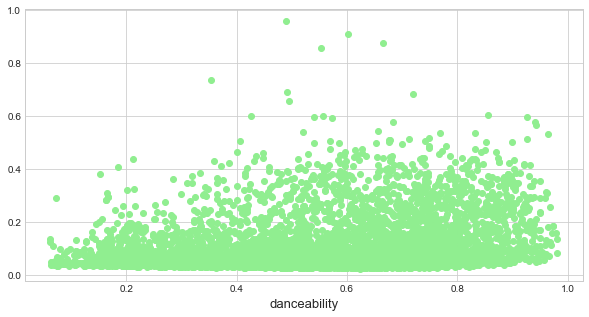

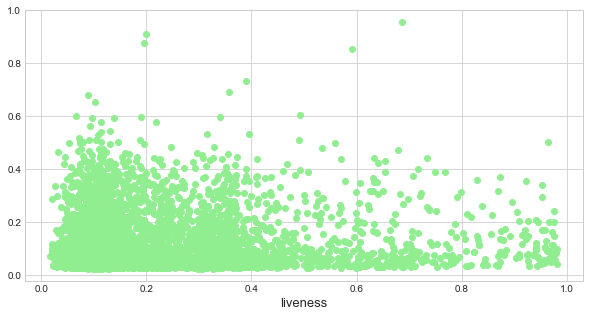

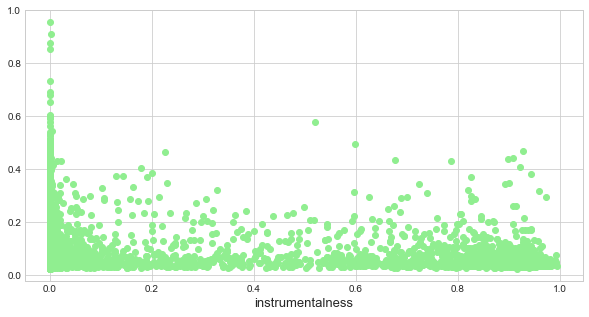

In [74]:
for feature in ['danceability','liveness','instrumentalness']:
    plt.figure(figsize=(10,5))
    plt.scatter(data[feature],data['speechiness'],color='lightgreen')
    plt.xlabel(feature,fontsize=13)
    plt.show()

Creating a new categorical variable to create valid bins for the "speechiness" variable (according to the guidelines put in the data description in Kaggle)
* Values > 0.66 = entirely of spoken words
* Values between 0.33 and 0.66 = both music and speech, either in sections or layered, including such cases as rap music
* Values below 0.33 = music and other non-speech-like tracks.

In [75]:
data['speech_bins']=data.speechiness.apply(lambda x: 'Spoken' if x>=0.66 else('Music and Speech' if (x>=0.33 and x<0.66) else 'Music(non-speech)'))

In [76]:
data.speech_bins.value_counts()

Music(non-speech)    5990
Music and Speech      291
Spoken                  7
Name: speech_bins, dtype: int64

Most of the songs last decade was Music (non speech), i.e., speechiness values less than 0.33. <br> Music (non-speech) might have dominant instrumentals ( even though the confidence might be low). <br> Out of curiosity, let's examine the "Spoken" (i.e., speechiness values above 0.66) tracks. The exclusive speech like recordings have speechiness closer to 1. Thus, the tracks under Spoken category might not mean that they all are talk-shows, etc. These could be songs that are more vocally inclined

In [77]:
data[data['speech_bins']=="Spoken"] # more of a vocal track

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,...,duration_ms,time_signature,chorus_hit,sections,hit,duration_min,dance_bins,valence_bins,energy_bins,speech_bins
73,Train Food,XXXTENTACION,0.492,0.712,9,-7.278,0,0.691,0.5640,0.000091,...,164083,3,31.63572,10,1,2.734717,Medium,Low,High,Spoken
424,Growing Pains,Alessia Cara,0.353,0.755,1,-6.276,0,0.733,0.0822,0.000000,...,193680,4,30.59169,10,1,3.228000,Low,Medium,High,Spoken
1418,ATM,J. Cole,0.719,0.497,8,-7.661,1,0.681,0.1150,0.000000,...,216727,4,36.33591,9,1,3.612117,High,Low,Medium,Spoken
2177,Metal Arms,Hannibal Buress,0.489,0.755,6,-8.658,0,0.956,0.9110,0.000044,...,150999,1,31.70716,6,0,2.516650,Medium,Low,High,Spoken
3026,Butting In,Illingsworth,0.601,0.777,7,-6.595,0,0.910,0.5650,0.002570,...,121678,4,22.35582,3,0,2.027967,Medium,Medium,High,Spoken
3311,Easy Ridin,ohbliv,0.666,0.721,8,-12.068,0,0.876,0.9240,0.000000,...,74958,4,44.26844,4,0,1.249300,Medium,High,High,Spoken
4137,Dad's a Psych - Live,Matty B,0.553,0.512,5,-12.900,0,0.854,0.8560,0.000000,...,171080,3,26.88181,8,0,2.851333,Medium,High,Medium,Spoken


In [78]:
data[data['speech_bins']=="Music and Speech"] # most rap songs

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,...,duration_ms,time_signature,chorus_hit,sections,hit,duration_min,dance_bins,valence_bins,energy_bins,speech_bins
14,Maze of Martyr (Official Dominator 2017 anthem...,Dj Mad Dog,0.320,0.990,1,-2.454,1,0.344,0.00902,0.00032,...,232541,4,41.48721,14,0,3.875683,Low,Low,High,Music and Speech
97,New Freezer,Rich The Kid Featuring Kendrick Lamar,0.884,0.698,0,-9.101,1,0.364,0.04050,0.00000,...,191938,4,24.50269,8,1,3.198967,High,Medium,Medium,Music and Speech
109,Doom Funk,LX Sweat,0.364,0.503,6,-18.607,1,0.346,0.40600,0.90000,...,208040,4,55.82411,8,0,3.467333,Low,Medium,Medium,Music and Speech
152,Comin Out Strong,Future Featuring The Weeknd,0.628,0.481,1,-7.775,1,0.475,0.29000,0.00000,...,254370,5,36.52520,13,1,4.239500,Medium,Low,Medium,Music and Speech
158,My Chick Bad,Ludacris Featuring Nicki Minaj,0.624,0.723,1,-6.782,1,0.378,0.17200,0.00000,...,216933,4,22.16186,9,1,3.615550,Medium,High,High,Music and Speech
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6241,Wishing,"DJ Drama Featuring Chris Brown, Skeme & Lyquin",0.477,0.647,3,-4.657,0,0.343,0.08720,0.00000,...,252307,4,52.98682,10,1,4.205117,Medium,Medium,Medium,Music and Speech
6254,I Need A Doctor,Dr. Dre Featuring Eminem & Skylar Grey,0.594,0.946,3,-4.521,1,0.452,0.08690,0.00000,...,283733,4,80.25895,10,1,4.728883,Medium,Low,High,Music and Speech
6290,Ice Melts,Drake Featuring Young Thug,0.813,0.551,6,-7.605,0,0.353,0.08000,0.00000,...,250770,4,46.13365,9,1,4.179500,High,Medium,Medium,Music and Speech
6320,I'm Awesome,Spose,0.478,0.933,0,-5.814,1,0.353,0.54000,0.00000,...,179774,4,34.78117,6,1,2.996233,Medium,Medium,High,Music and Speech


In [79]:
(data[['track','speechiness','artist','dance_bins']][data['speech_bins']=="Music(non-speech)"]).sort_values('speechiness')

,track,speechiness,artist,dance_bins
338,Heartbreak Warfare,0.0225,John Mayer,Medium
2926,Drink On It,0.0231,Blake Shelton,Medium
3243,Perfect,0.0232,Ed Sheeran,Medium
5929,I Wanna Make You Close Your Eyes,0.0232,Dierks Bentley,Medium
2385,Give In To Me,0.0234,Garrett Hedlund & Leighton Meester,Medium
...,...,...,...,...
63,Clique,0.3240,"Kanye West, Jay-Z, Big Sean",Medium
4372,If You Know You Know,0.3250,Pusha T,Medium
1666,New Level,0.3260,A$AP Ferg Featuring Future,Medium
950,R.I.C.O.,0.3270,Meek Mill Featuring Drake,High


In [80]:
# Low danceability and non speech songs
low_nonspeech=data[['track','speechiness','artist','dance_bins','hit']][(data['speech_bins']=="Music(non-speech)") & (data['dance_bins']=="Low")]
low_nonspeech

,track,speechiness,artist,dance_bins,hit
8,Holiday With HH,0.1700,No Bros,Low,0
9,My Last,0.1700,Big Sean Featuring Chris Brown,Low,1
12,"Theme From ""Bus Stop""",0.0373,Jackie Gleason,Low,0
27,The Healing Process,0.0336,Koh Lantana,Low,0
30,Sleep Hibernation,0.0428,Moon Laika,Low,0
...,...,...,...,...,...
6383,Shame,0.0368,Mikkel Metal,Low,0
6384,Gimme D' Road - Carnival Mix,0.1650,Calypso Rose,Low,0
6386,Vast Changes,0.0370,Regentum,Low,0
6393,Lotus Flowers,0.0342,Yolta,Low,0


In the whole dataset (hits and flops) , we saw that out of the non-speech tracks which amounts to 5990 rows of data, only 1187 are of low danceability. To see if the low dance and non-speech tracks are a more hit than the high/medium dance and non-speech tracks:

In [81]:
low_nonspeech[low_nonspeech['hit']==1]

,track,speechiness,artist,dance_bins,hit
9,My Last,0.1700,Big Sean Featuring Chris Brown,Low,1
36,Mr. Misunderstood,0.0450,Eric Church,Low,1
65,Mama's Song,0.0357,Carrie Underwood,Low,1
88,We Are The World 25: For Haiti,0.0882,Artists For Haiti,Low,1
140,Today,0.0381,Brad Paisley,Low,1
...,...,...,...,...,...
6216,The Christmas Song (Merry Christmas To You),0.0341,Nat King Cole,Low,1
6240,For The First Time In Forever,0.0344,Kristen Bell & Idina Menzel,Low,1
6269,V.S.O.P.,0.0577,K. Michelle,Low,1
6303,Lonely Boy,0.0680,The Black Keys,Low,1


Only 157 of the total 1187 low danceability and non speech songs were hits. So, we are starting to see some patterns that most of the hits are having more danceability (which is positively correlated with loudness). But, this might not always be the case, as sometimes variables that we haven't included in this dataset, like an event that might have boosted the artist's popularity or a certain trend , etc. might affect a track being a hit or not

In [82]:
pd.crosstab(data['speech_bins'],data['hit'])

hit,0,1
speech_bins,,
Music and Speech,89,202
Music(non-speech),2996,2994
Spoken,4,3


Music and Speech (speechiness values between 0.33 and 0.66) are the ones where we can say for sure that there are more hits

So, vaguely we can say that songs having music and speech (vocals) tend to make more hits

In [83]:
fig = data.plot.bar(data['speech_bins'],facet_row="hit",color='speech_bins',template='none')
fig.show()

### Top 10 tracks with high speechiness and their artists

In [84]:
top_10_speechiness= data.sort_values(by=['speechiness'],ascending=False).head(10)
fig = px.bar(top_10_speechiness, x="artist", y="speechiness", 
                title="Top 10 high speechiness artists and their respective songs",text='track',
             color="speechiness",color_continuous_scale="tealgrn")
fig.show()

__Acousticness__

A confidence measure from 0.0 to 1.0 of whether the track is acoustic. 1.0 represents high confidence the track is acoustic.

In [85]:
# correlation of loudness with other features
data[list(data.columns)].corr()['acousticness'][:].sort_values(ascending=False) 

acousticness        1.000000
instrumentalness    0.320468
sections            0.015304
mode                0.005727
chorus_hit          0.000731
key                -0.020480
duration_min       -0.041810
duration_ms        -0.041810
speechiness        -0.132718
liveness           -0.149679
valence            -0.163774
tempo              -0.185641
hit                -0.190823
time_signature     -0.194755
danceability       -0.202445
loudness           -0.647950
energy             -0.731906
Name: acousticness, dtype: float64

`Acousticness` is negatively correlated with `hit`, with a weak strength. It is positively correlated with `instrumentalness` and negatively correlated strongly with `energy` and `loudness`.

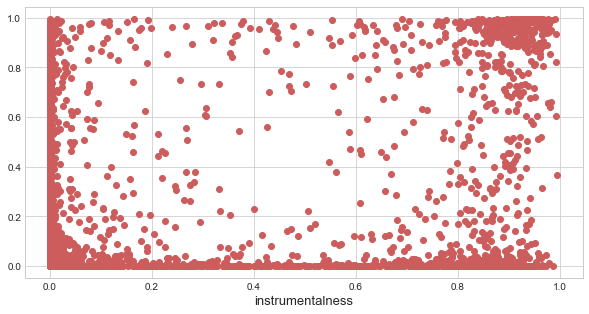

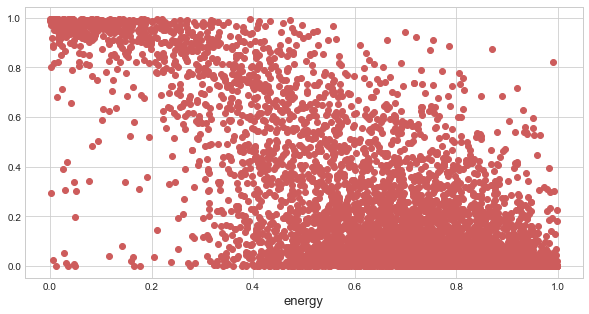

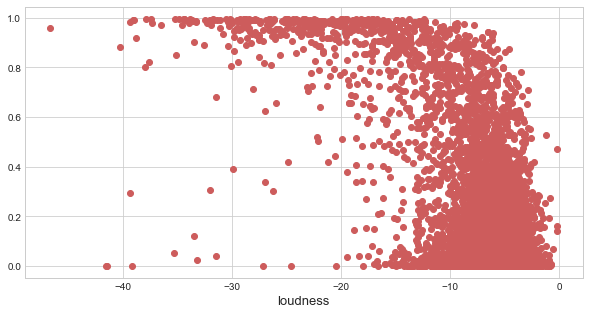

In [86]:
for feature in ['instrumentalness','energy','loudness']:
    plt.figure(figsize=(10,5))
    plt.scatter(data[feature],data['acousticness'],color='indianred')
    plt.xlabel(feature,fontsize=13)
    plt.show()

In [87]:
data['acoust_bins']=data.acousticness.apply(lambda x: 'High' if x>=0.7 else('Medium' if (x>=0.4 and x<0.7) else 'Low'))

In [88]:
data.acoust_bins.value_counts()

Low       4966
High       744
Medium     578
Name: acoust_bins, dtype: int64

In [89]:
pd.crosstab(data['acoust_bins'],data['hit'])

hit,0,1
acoust_bins,,
High,624,120
Low,2192,2774
Medium,273,305


* Most of the __High__ `acousticness` songs are flops
* Some(though not a lot) of the low acousticness songs are hits

_It is thus understood that for a track to become a hit, it should thus have low or atleast medium acousticness values_

### Top 10 tracks with high acousticness and their artists

In [90]:
top_10_acoustic=data.sort_values(by=['acousticness'],ascending=False).head(10)
fig = px.bar(top_10_acoustic, x="track", y="acousticness", 
                title="Top 10 high acousticness songs and their respective artists",text='artist',
             color="acousticness",color_continuous_scale="amp")
fig.show()

### Instrumentalness 

The closer the instrumentalness value is to 1.0, the greater likelihood the track contains no vocal content. Values above 0.5 are intended to represent instrumental tracks, but confidence is higher as the value approaches 1.0. 

In [91]:
# correlation of loudness with other features
data[list(data.columns)].corr()['instrumentalness'][:].sort_values(ascending=False)

instrumentalness    1.000000
acousticness        0.320468
duration_ms         0.174618
duration_min        0.174618
sections            0.110162
chorus_hit          0.088576
key                -0.014810
mode               -0.037071
liveness           -0.045945
tempo              -0.084320
time_signature     -0.136411
speechiness        -0.146653
energy             -0.293676
valence            -0.331186
danceability       -0.374657
hit                -0.500596
loudness           -0.537726
Name: instrumentalness, dtype: float64

`Instrumentalness` is negatively correlated with `hit` and `loudness` and is positively correlated with `acousticness`

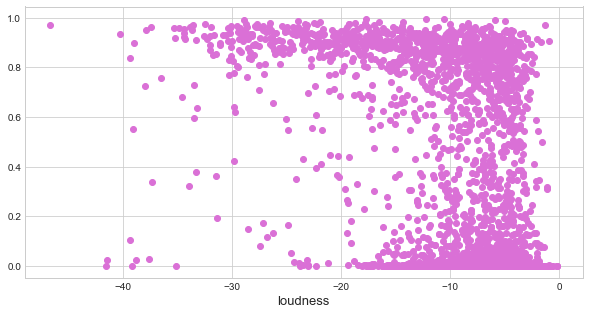

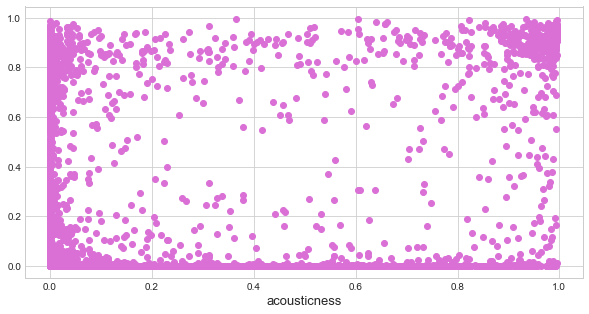

In [92]:
for feature in ['loudness','acousticness']:
    plt.figure(figsize=(10,5))
    plt.scatter(data[feature],data['instrumentalness'],color='orchid')
    plt.xlabel(feature,fontsize=13)
    plt.show()

In [93]:
data['instr_bins']=data.instrumentalness.apply(lambda x: 'High' if x>=0.7 else('Medium' if (x>=0.4 and x<0.7) else 'Low'))

In [94]:
data.instr_bins.value_counts()

Low       5130
High       914
Medium     244
Name: instr_bins, dtype: int64

In [95]:
pd.crosstab(data['instr_bins'],data['hit'])

hit,0,1
instr_bins,,
High,907,7
Low,1945,3185
Medium,237,7


_To make a hit, we need to have low instrumentalness values_

### Top 10 high instrumentalness artists and their respective songs

In [96]:
top_10_instrumentals=data.sort_values(by=['instrumentalness'],ascending=False).head(10)
fig = px.bar(top_10_instrumentals, x="track", y="instrumentalness", 
                title="Top 10 high instrumentalness artists and their respective songs",text='artist',
             color="instrumentalness",color_continuous_scale="tropic")
fig.show()

In [97]:
duplicate = top_10_instrumentals[top_10_instrumentals.duplicated()]
duplicate # Selecting duplicate rows except first 
# occurrence based on all columns

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,...,chorus_hit,sections,hit,duration_min,dance_bins,valence_bins,energy_bins,speech_bins,acoust_bins,instr_bins


__Liveness__

Higher liveness values represent an increased probability that the track was performed live. A value above 0.8 provides strong likelihood that the track is live.

In [98]:
data[list(data.columns)].corr()['liveness'][:].sort_values(ascending=False)

liveness            1.000000
energy              0.232541
loudness            0.126083
speechiness         0.119731
chorus_hit          0.046800
duration_min        0.045731
duration_ms         0.045731
tempo               0.040589
time_signature      0.026131
key                 0.022148
sections            0.010955
mode               -0.009191
valence            -0.020592
instrumentalness   -0.045945
hit                -0.065865
danceability       -0.112839
acousticness       -0.149679
Name: liveness, dtype: float64

`liveness` is negatively correlated with `hit` and `acousticness` and is positively correlated with `energy`

In [99]:
data['live_bins']=data.liveness.apply(lambda x: 'High' if x>=0.8 else('Medium' if (x>=0.4 and x<0.8) else 'Low'))

In [100]:
data.live_bins.value_counts()

Low       5731
Medium     452
High       105
Name: live_bins, dtype: int64

In [101]:
pd.crosstab(data['live_bins'],data['hit'])

hit,0,1
live_bins,,
High,81,24
Low,2766,2965
Medium,242,210


Since `liveness` is negatively correlated with `hit`, (as `liveness` increases, the chances of it being a hit decreases), _to make a hit song, we have to record the song not in front of a live audience_.

In [102]:
top_10_livetracks=data.sort_values(by=['liveness'],ascending=False).head(10)
fig = px.bar(top_10_livetracks, x="track", y="liveness", 
                title="Top 10 high liveness tracks and their respective artists",text='artist',
             color="liveness",color_continuous_scale="temps")
fig.show()

__Tempo__

 tempos usually range from around 30 bpm (very slow) to around 280 bpm (very fast) = from https://en.scratch-wiki.info/wiki/Tempo_(value)#:~:text=In%20traditional%20music%2C%20tempos%20usually,()%20Beats%20blocks%20will%20play.

In [103]:
data[list(data.columns)].corr()['tempo'][:].sort_values(ascending=False)

tempo               1.000000
energy              0.220236
loudness            0.195719
speechiness         0.118351
valence             0.054161
sections            0.046570
liveness            0.040589
hit                 0.039031
mode                0.029667
time_signature      0.025948
key                 0.012681
duration_min       -0.020263
duration_ms        -0.020263
danceability       -0.054875
chorus_hit         -0.063585
instrumentalness   -0.084320
acousticness       -0.185641
Name: tempo, dtype: float64

It is positively correlated with `hit` and `energy` and is negatively correlated with `acousticness`

In [104]:
hits['tempo'].mean()

123.52457580493885

In [105]:
data.tempo.describe()

count    6288.000000
mean      122.377311
std        29.914492
min        39.369000
25%        98.051250
50%       121.098500
75%       141.105750
max       210.977000
Name: tempo, dtype: float64

In [106]:
# trying to bin 'tempo'
data['tempo_bins']=data.tempo.apply(lambda x: 'High' if x>=132 else('Medium' if (x>=86 and x<132) else 'Low'))

In [107]:
data.tempo_bins.value_counts()

Medium    3379
High      2194
Low        715
Name: tempo_bins, dtype: int64

In [108]:
pd.crosstab(data['tempo_bins'],data['hit'])

hit,0,1
tempo_bins,,
High,1023,1171
Low,397,318
Medium,1669,1710


From above, we see that there is a light inclination for hits to have a higher temp. And since tempo is positively correlated with `energy`, to make a hit, we could use higher tempo values (generally). (But certainly there might be other factors determining the success of a track)

In [109]:
top_10_tempo=data.sort_values(by=['tempo'],ascending=False).head(10)
fig = px.bar(top_10_tempo, x="artist", y="tempo", 
                title="Top 10 high tempo tracks and their respective artists",text='track',
             color="tempo",color_continuous_scale="phase")
fig.show()

#### Getting to know the artists who had more than 1 songs that are hits (in 10-19s (a decade)

### artists with multiple hits

In [110]:
hits[hits['artist']=="Drake"]

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit,duration_min
15,Hotline Bling,Drake,0.891,0.625,2,-7.861,1,0.0558,0.002610,0.000176,0.0504,0.5480,134.967,267067,4,69.38968,8,1,4.451117
194,Know Yourself,Drake,0.733,0.412,11,-8.687,0,0.2250,0.196000,0.000000,0.3420,0.1790,114.413,275840,4,46.90366,9,1,4.597333
255,Blem,Drake,0.726,0.535,7,-7.804,0,0.0476,0.053300,0.000014,0.0984,0.3750,98.067,216558,4,39.88077,6,1,3.609300
319,Omerta,Drake,0.646,0.899,6,-2.232,1,0.2980,0.033700,0.000000,0.2320,0.6850,164.119,219507,4,24.14217,9,1,3.658450
343,Still Here,Drake,0.833,0.431,0,-9.604,1,0.1940,0.026700,0.000000,0.6330,0.2240,133.938,189853,3,28.67144,9,1,3.164217
433,Redemption,Drake,0.694,0.314,0,-7.820,1,0.1170,0.612000,0.000002,0.1170,0.3380,119.906,333947,4,33.03029,17,1,5.565783
708,Jorja Interlude,Drake,0.735,0.373,11,-10.478,1,0.1040,0.762000,0.002020,0.2880,0.2370,123.081,107673,4,63.41151,4,1,1.794550
737,Controlla,Drake,0.611,0.468,10,-11.084,0,0.1790,0.078100,0.000000,0.1010,0.3490,92.092,245227,4,41.10810,11,1,4.087117
822,Emotionless,Drake,0.413,0.677,1,-5.120,1,0.2550,0.024900,0.000000,0.0793,0.0845,172.501,302173,4,31.31506,11,1,5.036217
904,Summer Sixteen,Drake,0.594,0.460,1,-7.607,1,0.3820,0.003540,0.000027,0.1470,0.0541,146.274,202451,4,54.72466,8,1,3.374183


In [111]:
def count_artists(col,artist):
    count = 0
    for person in col:
        if (person==artist):
            count+=1
        else:
            continue
    return count

In [112]:
singer_counts={}
for artist in hits['artist']:
    singer_counts[artist]=count_artists(hits['artist'],artist)

In [114]:
# sorting singer_counts according to values in descending order
singer_counts=dict(sorted(singer_counts.items(), key=lambda item: item[1], reverse=True))
singer_counts

{'Drake': 50,
 'Glee Cast': 41,
 'Taylor Swift': 35,
 'Luke Bryan': 25,
 'The Weeknd': 24,
 'Post Malone': 23,
 'Jason Aldean': 22,
 'Blake Shelton': 20,
 'Ariana Grande': 19,
 'Eric Church': 17,
 'Carrie Underwood': 17,
 'XXXTENTACION': 17,
 'One Direction': 17,
 'Justin Bieber': 17,
 'Kenny Chesney': 16,
 'Lady Gaga': 16,
 'Rihanna': 16,
 'Chris Brown': 16,
 'Billie Eilish': 15,
 'J. Cole': 15,
 'Keith Urban': 15,
 'Lady Antebellum': 15,
 'Zac Brown Band': 14,
 'Nicki Minaj': 14,
 'Thomas Rhett': 14,
 'Kendrick Lamar': 14,
 'YoungBoy Never Broke Again': 14,
 'Chris Young': 14,
 'Bruno Mars': 13,
 'Demi Lovato': 13,
 'Jason Derulo': 13,
 'Miranda Lambert': 13,
 'Brad Paisley': 12,
 'Jake Owen': 12,
 'Katy Perry': 12,
 'Maroon 5': 12,
 'Dierks Bentley': 12,
 'Florida Georgia Line': 12,
 'Ed Sheeran': 11,
 'Imagine Dragons': 11,
 'Kelly Clarkson': 11,
 'Trey Songz': 11,
 'Tim McGraw': 11,
 'Kanye West': 11,
 'Eminem': 10,
 'OneRepublic': 10,
 'Future': 10,
 'Lee Brice': 10,
 'Selena Gom

In [115]:
# getting the top 10 singers (with most hits)
import heapq
top_10_singer_names = heapq.nlargest(10, singer_counts, key=singer_counts.get)

In [116]:
top_5_singer_names = heapq.nlargest(5, singer_counts, key=singer_counts.get)

In [117]:
# trying to put singer_counts in a new dataframe
max_hits_singers= pd.DataFrame({'Artists': list(singer_counts.keys()),
                                        'Number of hits': list(singer_counts.values())})
max_hits_singers

,Artists,Number of hits
0,Drake,50
1,Glee Cast,41
2,Taylor Swift,35
3,Luke Bryan,25
4,The Weeknd,24
...,...,...
1709,Wham!,1
1710,Flo Rida & 99 Percent,1
1711,Trippie Redd Featuring DaBaby,1
1712,Liam Payne Featuring Quavo,1


In [118]:
max_hits_singers[:10]

,Artists,Number of hits
0,Drake,50
1,Glee Cast,41
2,Taylor Swift,35
3,Luke Bryan,25
4,The Weeknd,24
5,Post Malone,23
6,Jason Aldean,22
7,Blake Shelton,20
8,Ariana Grande,19
9,Eric Church,17


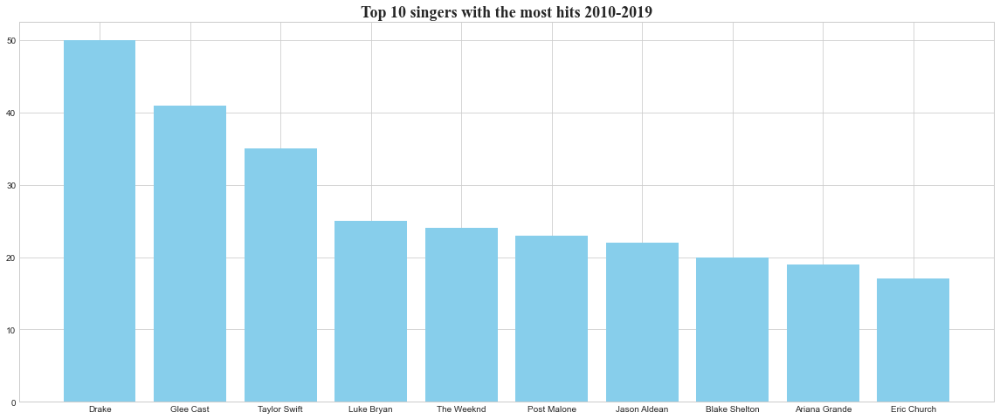

In [119]:
plt.bar(max_hits_singers['Artists'][:10],max_hits_singers['Number of hits'][:10],color='skyblue')
plt.title("Top 10 singers with the most hits 2010-2019",fontsize = 18,fontname='Times New Roman',fontweight="bold")
plt.show()

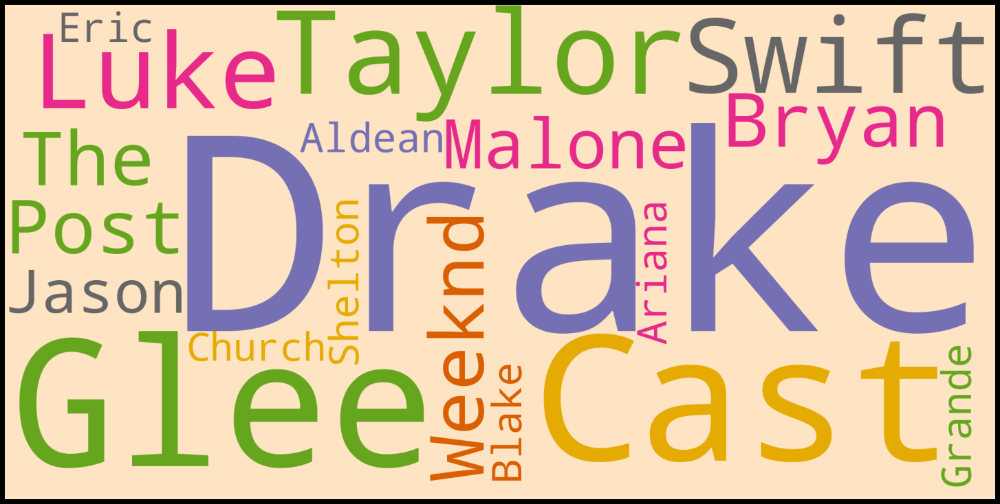

In [120]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt
text = max_hits_singers['Artists'][:10]
max_words=400
wordcloud = WordCloud(
    width = 2000,
    height = 1000,
    max_words = max_words,
    background_color = 'bisque',
    colormap= "Dark2"
    ,stopwords = ['Name','Artists','dtype','object'],relative_scaling=0,random_state=2).generate(str(text))
fig = plt.figure(
    figsize = (20, 10),
    facecolor = 'k',
    edgecolor = 'k')
plt.imshow(wordcloud)
plt.axis('off')
plt.tight_layout(pad=0)
plt.show()

## Getting the features ready for modeling

In [121]:
# see the current columns we have in our dataset
data.columns

Index(['track', 'artist', 'danceability', 'energy', 'key', 'loudness', 'mode',
       'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'duration_ms', 'time_signature', 'chorus_hit',
       'sections', 'hit', 'duration_min', 'dance_bins', 'valence_bins',
       'energy_bins', 'speech_bins', 'acoust_bins', 'instr_bins', 'live_bins',
       'tempo_bins'],
      dtype='object')

In [122]:
## dropping the columns that we don't want to use for modeling
data=data.drop(columns=['duration_min', 'dance_bins', 'valence_bins',
       'energy_bins', 'speech_bins', 'acoust_bins', 'instr_bins', 'live_bins',
       'tempo_bins'],axis=1)

In [123]:
data.head()

,track,artist,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections,hit
0,Wild Things,Alessia Cara,0.741,0.626,1,-4.826,0,0.0886,0.02000,0.000,0.0828,0.706,108.029,188493,4,41.18681,10,1
1,Surfboard,Esquivel!,0.447,0.247,5,-14.661,0,0.0346,0.87100,0.814,0.0946,0.250,155.489,176880,3,33.18083,9,0
2,Love Someone,Lukas Graham,0.550,0.415,9,-6.557,0,0.0520,0.16100,0.000,0.1080,0.274,172.065,205463,4,44.89147,9,1
3,Music To My Ears (feat. Tory Lanez),Keys N Krates,0.502,0.648,0,-5.698,0,0.0527,0.00513,0.000,0.2040,0.291,91.837,193043,4,29.52521,7,0
4,Juju On That Beat (TZ Anthem),Zay Hilfigerrr & Zayion McCall,0.807,0.887,1,-3.892,1,0.2750,0.00381,0.000,0.3910,0.780,160.517,144244,4,24.99199,8,1


In [124]:
data.shape

(6288, 18)

In [125]:
data[list(data.columns)].corr()['hit'][:].sort_values(ascending=False)

hit                 1.000000
danceability        0.386662
loudness            0.328659
valence             0.199458
time_signature      0.130047
speechiness         0.095724
energy              0.064461
tempo               0.039031
mode                0.030237
key                 0.007785
liveness           -0.065865
chorus_hit         -0.083683
sections           -0.109236
duration_ms        -0.183102
acousticness       -0.190823
instrumentalness   -0.500596
Name: hit, dtype: float64

hit is least correlated with key , mode , tempo, energy, speechiness, liveness, chorus hit 

__Histogram of numerical features__

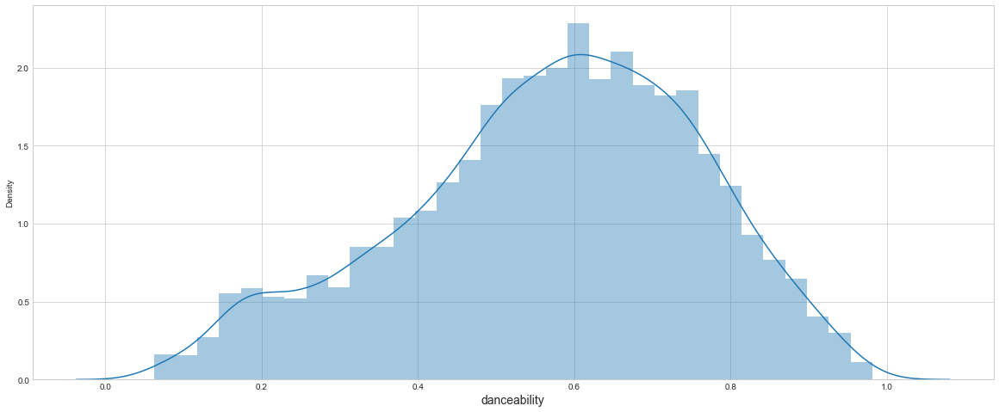

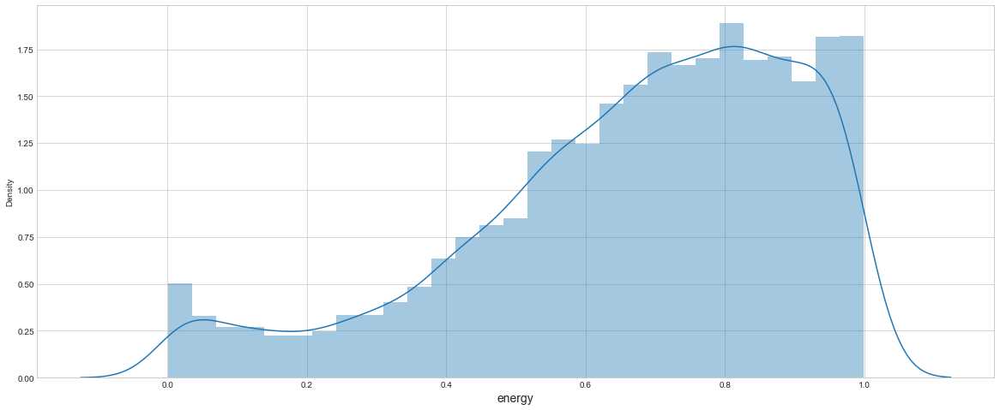

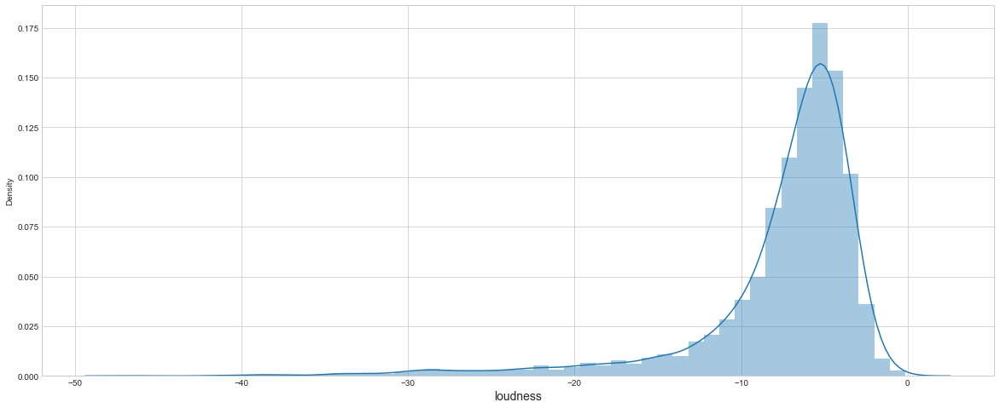

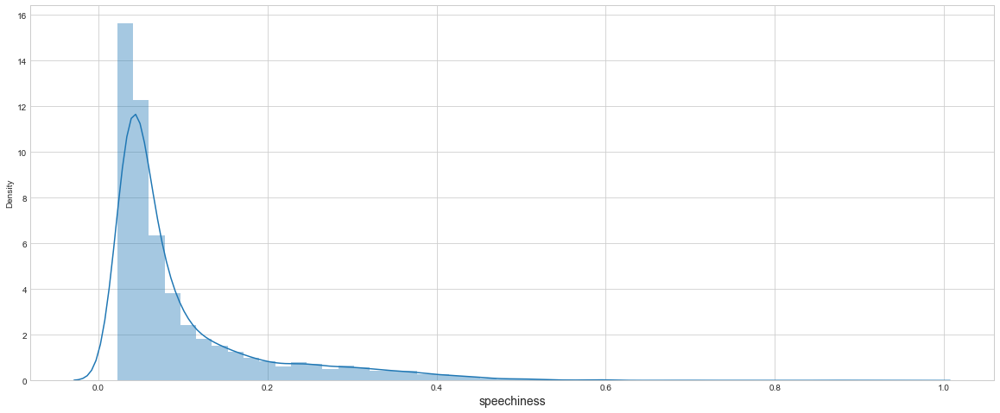

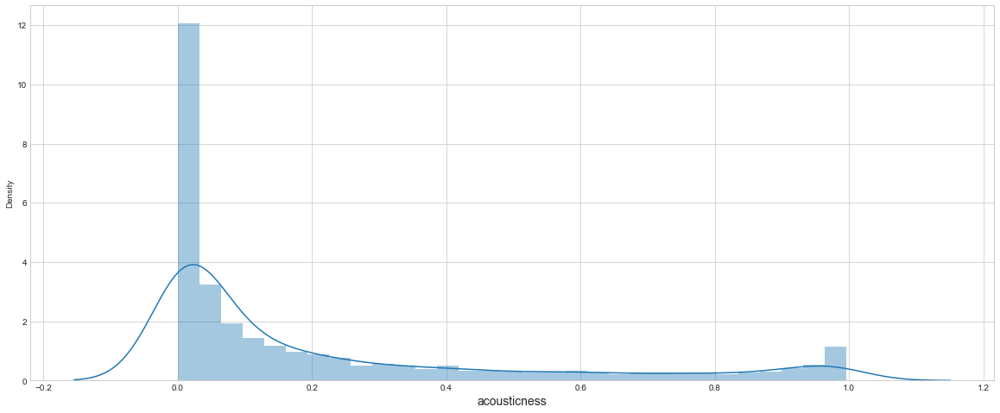

...

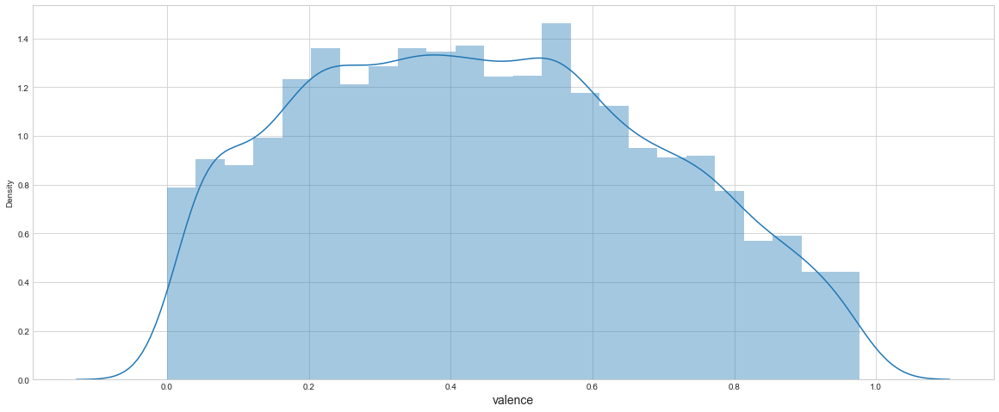

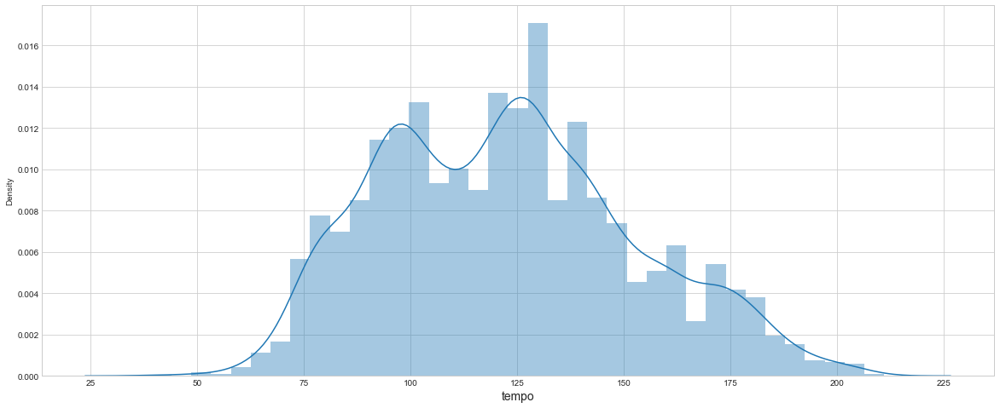

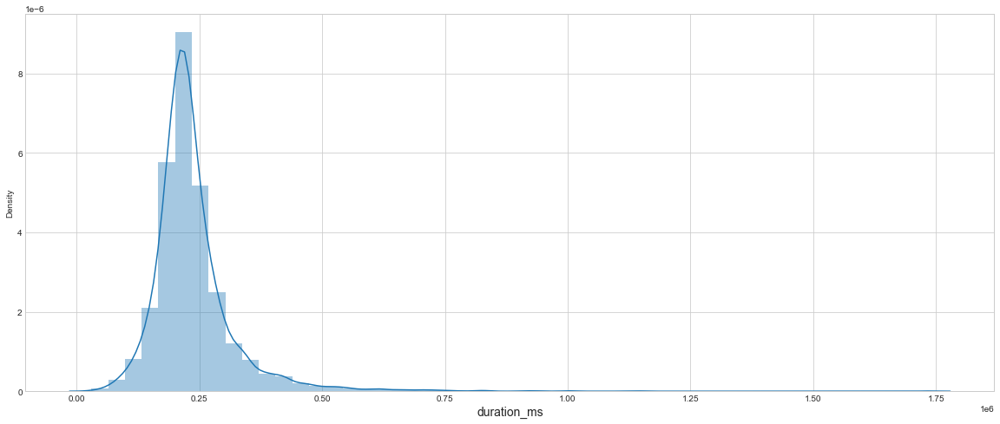

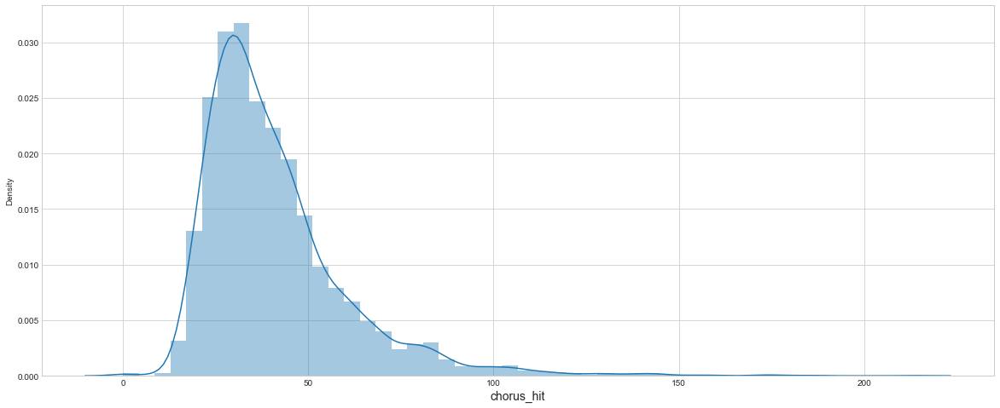

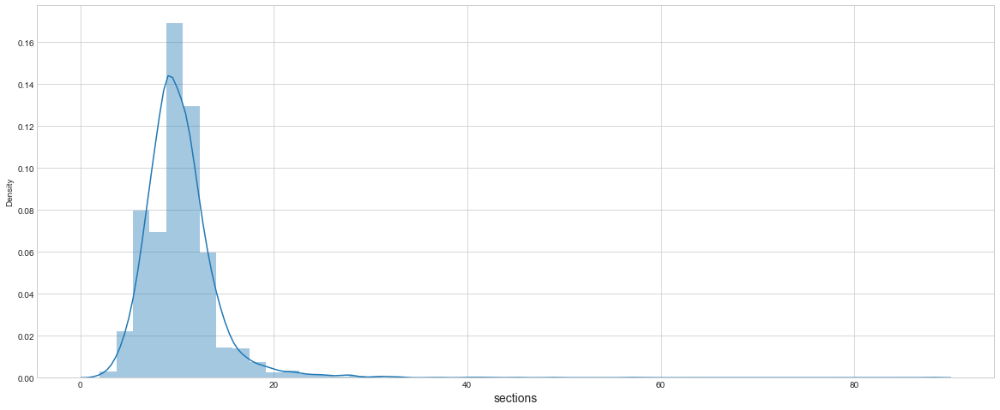

In [126]:
num_features=['danceability','energy','loudness','speechiness','acousticness','instrumentalness','liveness','valence','tempo','duration_ms','chorus_hit','sections']
for feature in num_features:
    sns.distplot(data[feature])
    #fig = plt.figure()
    plt.xlabel(feature,fontsize=14)
    plt.show()

Feature:  danceability


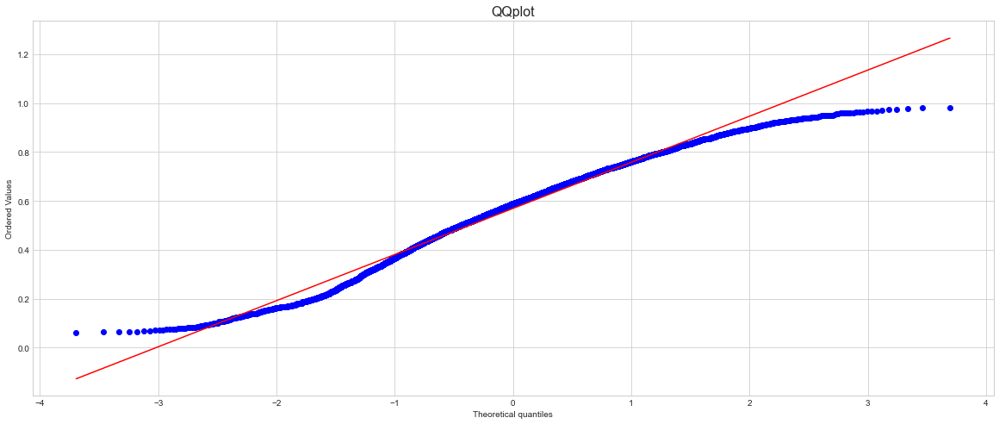

Feature:  energy


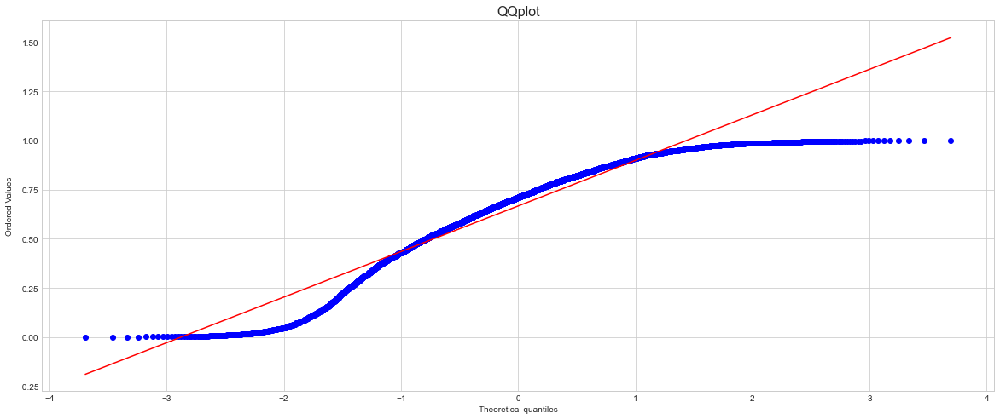

Feature:  loudness


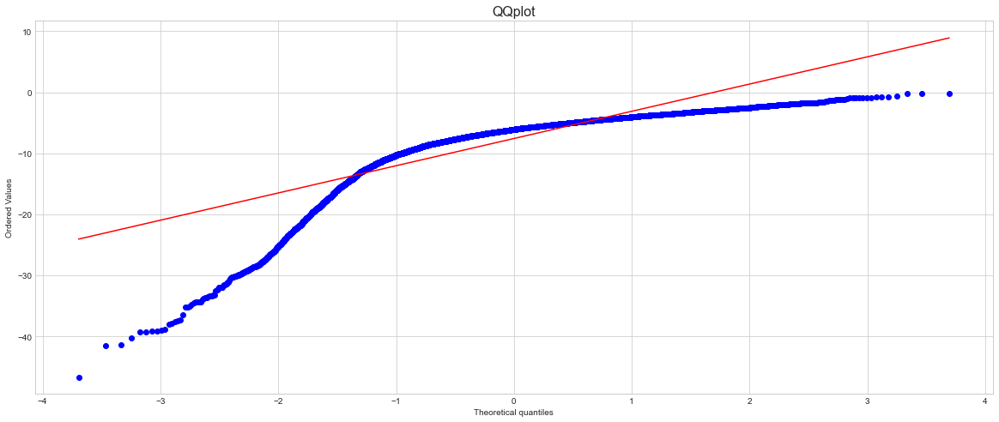

Feature:  speechiness


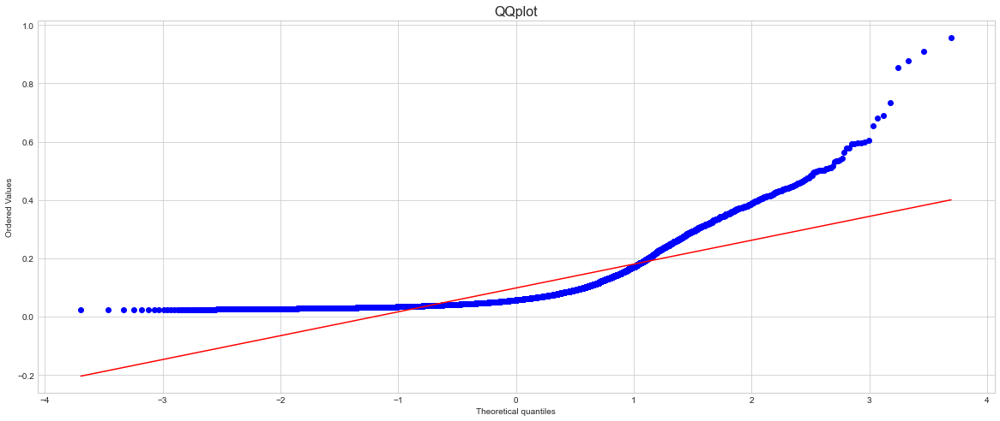

Feature:  acousticness


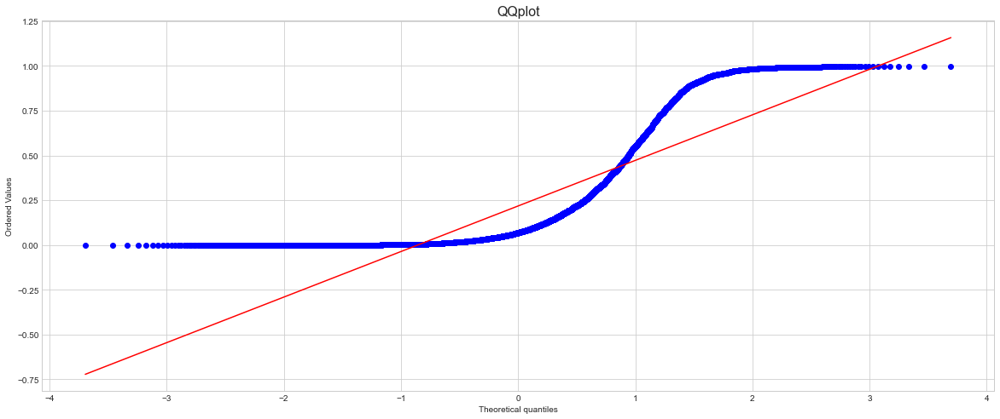

Feature:  instrumentalness


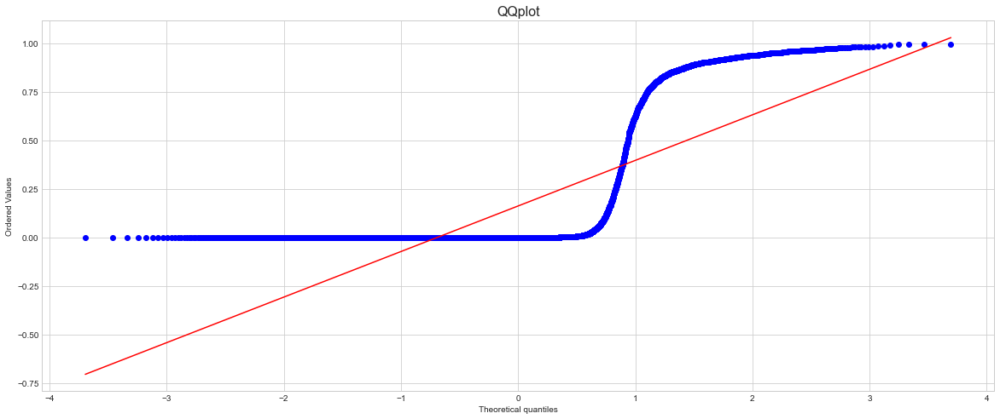

Feature:  liveness


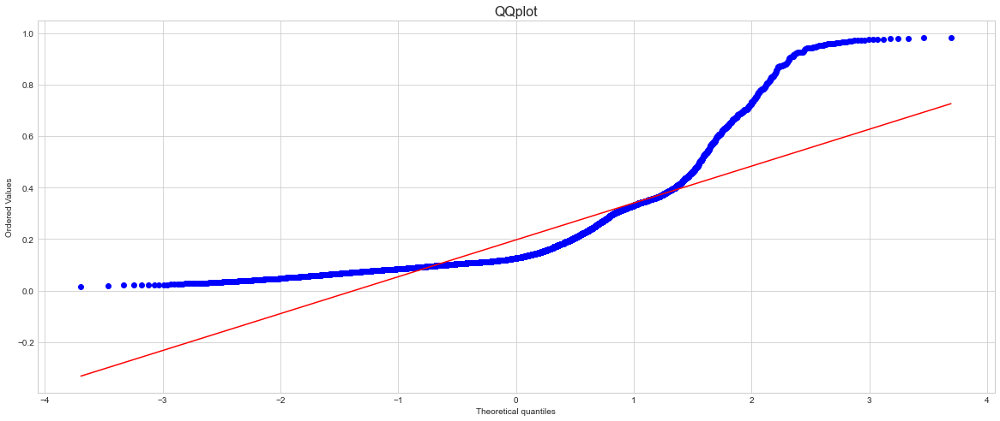

Feature:  valence


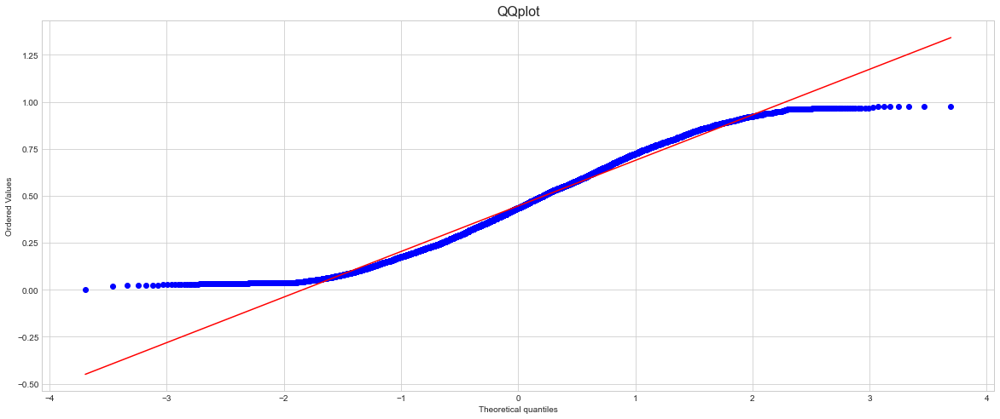

Feature:  tempo


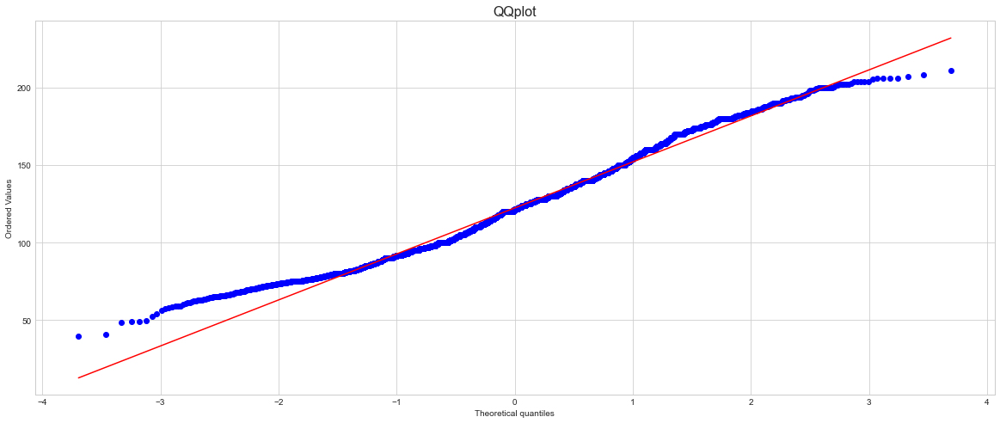

Feature:  duration_ms


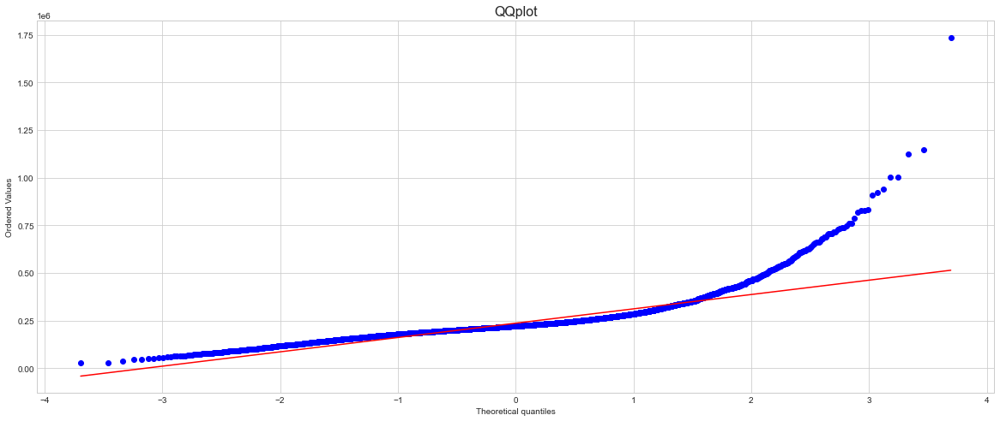

Feature:  chorus_hit


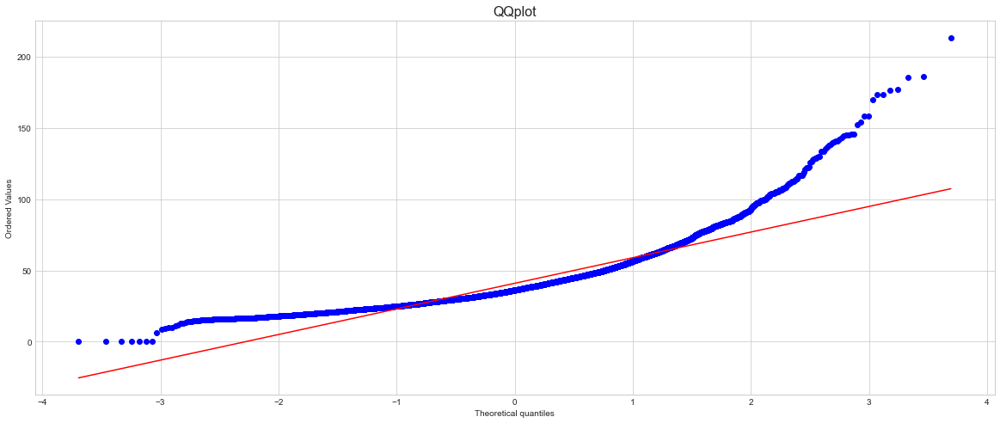

Feature:  sections


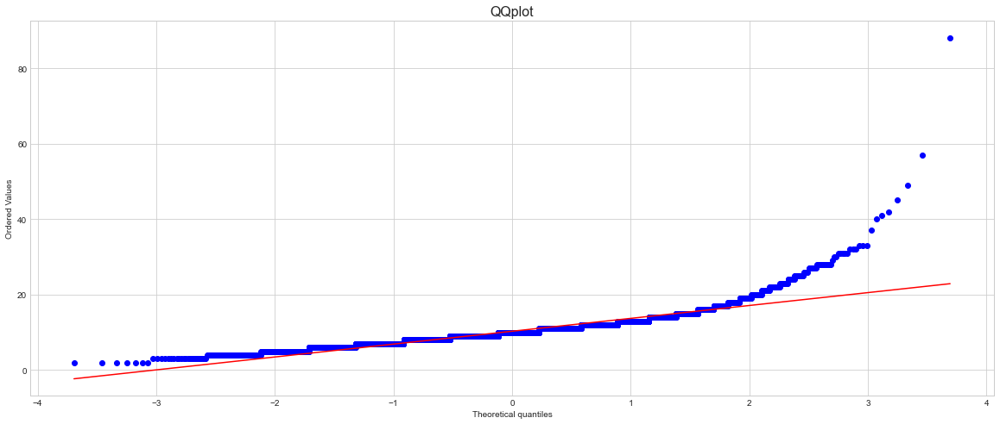

In [127]:
from scipy import stats
for feature in num_features:
    print("Feature: ",feature)
    org = stats.probplot(data[feature],plot=plt)
    plt.title("QQplot",fontsize=16)
    plt.show()

Most of the features are non normal. Since the models that we are going to be using doesn't need to have non-normal variables, we don't go into transforming them.

### Splitting the data into features and target

In [128]:

X_feat = data[['danceability', 'energy', 'key', 'loudness', 'mode','speechiness', 'acousticness', 'instrumentalness', 'liveness','valence', 'tempo', 'duration_ms', 'time_signature', 'chorus_hit','sections']]
y = data['hit']
print(X_feat.head())
print()
print(y.head())

   danceability  energy  key  loudness  mode  speechiness  acousticness  \
0         0.741   0.626    1    -4.826     0       0.0886       0.02000   
1         0.447   0.247    5   -14.661     0       0.0346       0.87100   
2         0.550   0.415    9    -6.557     0       0.0520       0.16100   
3         0.502   0.648    0    -5.698     0       0.0527       0.00513   
4         0.807   0.887    1    -3.892     1       0.2750       0.00381   

   instrumentalness  liveness  valence    tempo  duration_ms  time_signature  \
0             0.000    0.0828    0.706  108.029       188493               4   
1             0.814    0.0946    0.250  155.489       176880               3   
2             0.000    0.1080    0.274  172.065       205463               4   
3             0.000    0.2040    0.291   91.837       193043               4   
4             0.000    0.3910    0.780  160.517       144244               4   

   chorus_hit  sections  
0    41.18681        10  
1    33.18083   

## Logistic Regression

* There is no need to transform the non normal variables for Logistic Regression ( https://www.researchgate.net/post/Should_I_transform_non-normal_independent_variables_in_logistic_regression)
* Standardizing is also not required for logistic regression (but could be done)
* An assumption of Logistic Regression is that there is minimal or no multicollinearity among the independent variables.


In [129]:
## checking for multicollinearity using vif (variance inflation factor - show the correlation of a variable with a group of other variables.)

from statsmodels.stats.outliers_influence import variance_inflation_factor

def calc_vif(X):
    # a dataframe to store the vif values of the features
    vif = pd.DataFrame()
    vif["variables"] = X_feat.columns # col for feature names
    vif["VIF"] = [variance_inflation_factor(X_feat.values, i) for i in range(X_feat.shape[1])]

    return(vif)
# from https://www.analyticsvidhya.com/blog/2020/03/what-is-multicollinearity/

Before scaling

In [130]:
X_feat = data[['danceability', 'energy', 'key', 'loudness', 'mode','speechiness', 'acousticness', 'instrumentalness', 'liveness','valence', 'tempo', 'duration_ms', 'time_signature', 'chorus_hit','sections']]
calc_vif(X_feat)

,variables,VIF
0,danceability,15.623087
1,energy,27.533420
2,key,3.181593
3,loudness,9.021425
4,mode,2.905923
5,speechiness,2.237868
6,acousticness,3.345129
7,instrumentalness,2.042343
8,liveness,2.645624
9,valence,6.817540


* VIF exceeding 5 or 10 indicates high multicollinearity between this independent variable and the others

To reduce high VIFs produced by interaction and higher-order terms, you can standardize the continuous predictor variables. Standardizing is done below before fitting the model, after which I have calculated the VIFs again (source: https://blog.minitab.com/en/adventures-in-statistics-2/what-are-the-effects-of-multicollinearity-and-when-can-i-ignore-them )

For scaling the variables, we use the StandardScaler.<br> Min- Max tries to get the values closer to mean. But when there are outliers in the data which are important and we don’t want to loose their impact ,we go with Z score normalization. (from https://medium.com/@TheDataGyan/day-8-data-transformation-skewness-normalization-and-much-more-4c144d370e55 )

In [131]:
feature = [feature for feature in data.columns if feature not in ["hit","artist","track"]]
print(feature)
from sklearn.preprocessing import StandardScaler 
scaler = StandardScaler()
scaler.fit(data[feature])

['danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'time_signature', 'chorus_hit', 'sections']


StandardScaler()

In [132]:
num_features

['danceability',
 'energy',
 'loudness',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'duration_ms',
 'chorus_hit',
 'sections']

In [133]:
# from https://www.kaggle.com/sarthaktyagi01/spotify-hit-prediction
data = pd.concat([data[["hit","artist","track"]].reset_index(drop= True),pd.DataFrame(scaler.transform(data[feature]),columns = feature)],axis=1)

In [134]:
X_feat = data[['danceability', 'energy', 'key', 'loudness', 'mode','speechiness', 'acousticness', 'instrumentalness', 'liveness','valence', 'tempo', 'duration_ms', 'time_signature', 'chorus_hit','sections']]
calc_vif(X_feat)

,variables,VIF
0,danceability,1.817308
1,energy,4.250192
2,key,1.023834
3,loudness,3.729064
4,mode,1.041021
5,speechiness,1.115360
6,acousticness,2.460056
7,instrumentalness,1.628172
8,liveness,1.099955
9,valence,1.599170


* Hence,we can confirm that there is no multicollinearity as there are no VIF values exceeding 5 or 10

In [135]:
data.head()

,hit,artist,track,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections
0,1,Alessia Cara,Wild Things,0.901836,-0.171690,-1.184781,0.523126,-1.352732,-0.099526,-0.667130,-0.511064,-0.687955,1.060254,-0.479682,-0.554120,0.183098,0.011534,-0.077776
1,0,Esquivel!,Surfboard,-0.642269,-1.751993,-0.076453,-1.352218,-1.352732,-0.651926,2.203697,2.062469,-0.616899,-0.797072,1.106966,-0.689876,-2.457540,-0.397977,-0.342703
2,1,Lukas Graham,Love Someone,-0.101307,-1.051489,1.031875,0.193058,-1.352732,-0.473930,-0.191470,-0.511064,-0.536208,-0.699318,1.661123,-0.355741,0.183098,0.201030,-0.342703
3,0,Keys N Krates,Music To My Ears (feat. Tory Lanez),-0.353406,-0.079957,-1.461863,0.356853,-1.352732,-0.466769,-0.717293,-0.511064,0.041877,-0.630076,-1.021001,-0.500931,0.183098,-0.584965,-0.872557
4,1,Zay Hilfigerrr & Zayion McCall,Juju On That Beat (TZ Anthem),1.248471,0.916593,-1.184781,0.701222,0.739245,1.807277,-0.721746,-0.511064,1.167938,1.361663,1.275058,-1.071391,0.183098,-0.816842,-0.607630


### Splitting into training and testing data

In [137]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X_feat,y, test_size=0.2,random_state=11)

In [138]:
X_train.shape

(5030, 15)

In [139]:
y_train

6207    0
5459    0
1945    0
997     1
3110    1
       ..
1298    0
4071    1
5282    1
3816    0
1954    1
Name: hit, Length: 5030, dtype: int64

In [140]:
from sklearn.linear_model import LogisticRegression
LR_classifier = LogisticRegression()
LR_classifier.fit(X_train,y_train)

LogisticRegression()

In [141]:
y_pred = LR_classifier.predict(X_test)

In [142]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test,y_pred)

array([[466, 157],
       [ 74, 561]], dtype=int64)

In [143]:
from sklearn.metrics import precision_recall_fscore_support as score
precision, recall, fscore, train_support = score(y_test, y_pred, pos_label=1, average='binary')
print('Precision: {} / Recall: {} / Accuracy: {}'.format(
     round(precision, 3), round(recall, 3), round((y_pred==y_test).sum()/len(y_pred), 3)))

Precision: 0.781 / Recall: 0.883 / Accuracy: 0.816


In [145]:
print('Train Accuracy:',LR_classifier.score(X_train,y_train))
print("Test accuracy: ", LR_classifier.score(X_test,y_test))

Train Accuracy: 0.8055666003976143
Test accuracy:  0.8163751987281399


[[466 157]
 [ 74 561]]


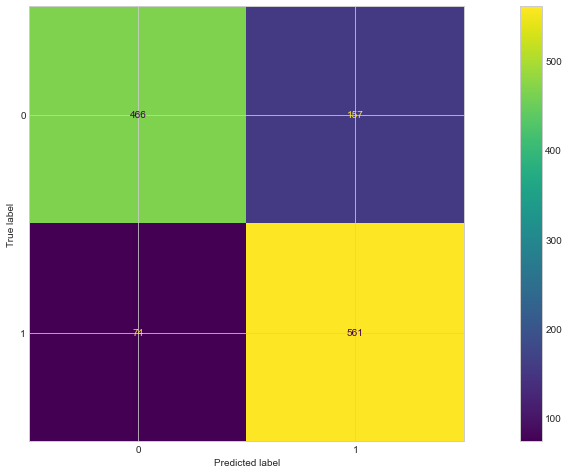

In [154]:
# plotting the confusion matrix
from sklearn.metrics import plot_confusion_matrix
plot_confusion_matrix(LR_classifier,X_test,y_test,cmap='viridis')
cf.ax_.set_title('Confusion Matrix')
print(cf.confusion_matrix)
plt.show()

In [149]:
from sklearn.metrics import classification_report, confusion_matrix
print('Classification Report \n\n',classification_report(y_test,y_pred))
print('\nConfussion matrix:\n',confusion_matrix(y_test, y_pred))

Classification Report 

               precision    recall  f1-score   support

           0       0.86      0.75      0.80       623
           1       0.78      0.88      0.83       635

    accuracy                           0.82      1258
   macro avg       0.82      0.82      0.82      1258
weighted avg       0.82      0.82      0.82      1258


Confussion matrix:
 [[466 157]
 [ 74 561]]


* The accuracy is given as 82%
* Support is the number of samples of true response that lie in that class
* Out of 623 occurences of 0 class, model correctly predicted 466 of them and predicted 157 of them as 1
* Out of 635 occurences of class 1 (hits), the model correctly predicted 561 of them and predicted 74 of them as flops (FN). So, this model is doing well in predicting class 1 (the hits, hence , less FN than FP). 
* The model has a good and better recall for class 1.
* Precision (TP/(TP+FP)) is more for class 0 than for class 1. Precision is given more importance when you value FP more than FN.
* f1 score is the harmonic mean of precision and recall, and it is more for class 1 than for class 0

In [156]:
# FPR = FP / (FP + TN) , i.e., False Positive Rate
lr_FPR = 157/ (157 + 466)
print("FPR: ", lr_FPR)
# TPR = TP / (TP + FN), i.e., True Positive rate or Sensitivity or Recall
lr_TPR = 561/ (561+74) 
print("TPR: ",lr_TPR)

FPR:  0.2520064205457464
TPR:  0.8834645669291339


In [157]:
from sklearn import metrics
print('Logistic loss: %.2f' %metrics.log_loss(y_test,y_pred))

Logistic loss: 6.34


#### ROC - AUC curve for Logistic Regression

In [158]:
from sklearn.metrics import roc_curve,roc_auc_score

No Skill: ROC AUC=0.500
Logistic: ROC AUC=0.884


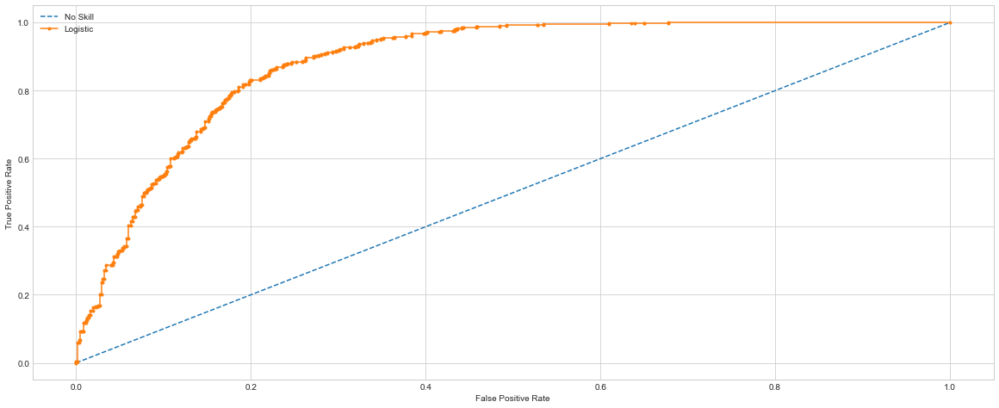

In [159]:
# generate a no skill prediction (majority class)
ns_probs = [0 for _ in range(len(y_test))]
# probabilities
lr_probs = LR_classifier.predict_proba(X_test)
# keep probabilities for the positive outcome only
lr_probs = lr_probs[:, 1]
# calculate scores 
ns_auc = roc_auc_score(y_test, ns_probs)
lr_auc = roc_auc_score(y_test, lr_probs)
# summarize scores
print('No Skill: ROC AUC=%.3f' % (ns_auc))
print('Logistic: ROC AUC=%.3f' % (lr_auc))
# calculate roc curves
ns_fpr, ns_tpr, _ = roc_curve(y_test, ns_probs)
lr_fpr, lr_tpr, thresholds_lr = roc_curve(y_test, lr_probs)
close_zero_lr = np.argmin(np.abs(thresholds_lr))
# plot the roc curve for the model
plt.plot(ns_fpr, ns_tpr, linestyle='--', label='No Skill')
plt.plot(lr_fpr, lr_tpr, marker='.', label='Logistic')
# axis labels
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
# show the legend
plt.legend()
# show the plot
plt.show()

## from https://machinelearningmastery.com/roc-curves-and-precision-recall-curves-for-classification-in-python/

The Logistic Regression Model has a AUC score of 0.85. We can use the AUC score to compare the different models and get the best one

In [161]:
X_train.columns

Index(['danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
       'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
       'duration_ms', 'time_signature', 'chorus_hit', 'sections'],
      dtype='object')

In [188]:
print(LR_classifier.coef_)

[[ 0.58748496 -1.34508132  0.02210734  1.83888181  0.08177076  0.00747479
  -0.46872207 -2.32699815 -0.125501   -0.12734257  0.07799092 -0.21074011
   0.17873832 -0.01926548 -0.04353096]]


Loudness has the highest positive coefficient, followed by danceability. Instrumentalness has the highest negative coefficient, followed by energy.

##### Logistic Regression with statsmodels

In [162]:
import statsmodels.api as sm

In [163]:
x = sm.add_constant(X_feat)

In [164]:
x # with added constant

,const,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature,chorus_hit,sections
0,1.0,0.901836,-0.171690,-1.184781,0.523126,-1.352732,-0.099526,-0.667130,-0.511064,-0.687955,1.060254,-0.479682,-0.554120,0.183098,0.011534,-0.077776
1,1.0,-0.642269,-1.751993,-0.076453,-1.352218,-1.352732,-0.651926,2.203697,2.062469,-0.616899,-0.797072,1.106966,-0.689876,-2.457540,-0.397977,-0.342703
2,1.0,-0.101307,-1.051489,1.031875,0.193058,-1.352732,-0.473930,-0.191470,-0.511064,-0.536208,-0.699318,1.661123,-0.355741,0.183098,0.201030,-0.342703
3,1.0,-0.353406,-0.079957,-1.461863,0.356853,-1.352732,-0.466769,-0.717293,-0.511064,0.041877,-0.630076,-1.021001,-0.500931,0.183098,-0.584965,-0.872557
4,1.0,1.248471,0.916593,-1.184781,0.701222,0.739245,1.807277,-0.721746,-0.511064,1.167938,1.361663,1.275058,-1.071391,0.183098,-0.816842,-0.607630
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6283,1.0,-2.086585,-1.289160,1.031875,-1.308170,0.739245,-0.656018,2.254299,2.543030,0.704266,-1.668305,-1.675084,-0.994085,0.183098,-0.851816,-0.872557
6284,1.0,1.789433,-1.255803,-1.184781,-0.454684,0.739245,-0.043263,-0.398601,-0.511064,0.385115,1.198739,-0.079978,-0.980724,0.183098,-0.430830,-0.607630
6285,1.0,0.786290,0.570511,1.308957,0.569843,0.739245,-0.642719,-0.690070,-0.511054,-0.349535,0.648873,-0.079510,-0.095088,0.183098,-1.034656,-0.872557
6286,1.0,0.161296,-2.043869,0.477711,-1.620887,0.739245,-0.431989,2.601767,2.233195,-0.289318,0.465584,-0.078474,-0.263109,0.183098,-0.987633,0.981932


In [165]:
y = list(y) 

In [166]:
model = sm.Logit(y, x)

In [167]:
result = model.fit(method='newton')

Optimization terminated successfully.
         Current function value: 0.436201
         Iterations 9


In [168]:
result.params.sort_values(ascending=False)

loudness            1.906233
danceability        0.599193
time_signature      0.209632
tempo               0.091584
mode                0.081465
key                 0.017352
sections            0.014904
speechiness         0.004327
chorus_hit         -0.021962
liveness           -0.071767
valence            -0.132063
duration_ms        -0.231726
acousticness       -0.474047
const              -1.047528
energy             -1.384495
instrumentalness   -2.485965
dtype: float64

In [169]:
print(result.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 6288
Model:                          Logit   Df Residuals:                     6272
Method:                           MLE   Df Model:                           15
Date:                Sun, 20 Jun 2021   Pseudo R-squ.:                  0.3706
Time:                        19:12:36   Log-Likelihood:                -2742.8
converged:                       True   LL-Null:                       -4357.5
Covariance Type:            nonrobust   LLR p-value:                     0.000
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -1.0475      0.093    -11.309      0.000      -1.229      -0.866
danceability         0.5992      0.050     12.042      0.000       0.502       0.697
energy              -1.3845 

We can also make out the significant factors from above as well

The features that are not significant for this logistic regression model are : <br> key, speechiness, chorus_hit and sections

## Decision Tree Classifier

In [177]:
from sklearn.tree import DecisionTreeClassifier

DT_classifier=DecisionTreeClassifier(random_state=90)
DT_classifier= DT_classifier.fit(X_train,y_train)

In [178]:
import os

os.environ['PATH'] = os.environ['PATH']+';'+os.environ['CONDA_PREFIX']+r"\Library\bin\graphviz"

In [179]:
from six import StringIO  
from IPython.display import Image  
from sklearn.tree import export_graphviz
import pydotplus
dot_data = StringIO()
export_graphviz(DT_classifier, out_file=dot_data,  
                filled=True, rounded=True,
                special_characters=True, feature_names = X_train.columns,class_names=['0','1'])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('tree.png')
Image(graph.create_png())

In [180]:
y_pred_DT = DT_classifier.predict(X_test)

In [181]:
print("Classification report\n\n",classification_report(y_test,y_pred_DT))
print('\nConfussion matrix:\n',confusion_matrix(y_test, y_pred_DT))

Classification report

               precision    recall  f1-score   support

           0       0.76      0.79      0.77       623
           1       0.78      0.75      0.77       635

    accuracy                           0.77      1258
   macro avg       0.77      0.77      0.77      1258
weighted avg       0.77      0.77      0.77      1258


Confussion matrix:
 [[492 131]
 [158 477]]


* The accuracy for Decision Trees is 77%
* Out of 623 occurences of 0 class, model correctly predicted 492 of them and predicted 131 of them as 1
* Out of 635 occurences of class 1 (hits), the model correctly predicted 477 of them and predicted 158 of them as flops (FN). 
* The model has more recall for class 0 than 1.
* Precision (TP/(TP+FP)) is more for class 1 than for class 0. Precision is given more importance when you value FP more than FN.
* f1 score is the harmonic mean of precision and recall, and it is same for class 1 and class 0

In [182]:
# FPR = FP / (FP + TN)
dt_FPR = 131 / (131 + 492)
dt_FPR

0.2102728731942215

In [183]:
DT_classifier.predict_proba(X_test)[:,1]

array([0., 1., 0., ..., 1., 0., 1.])

### ROC AUC for Logistic Regression vs Decision Tree Classifier

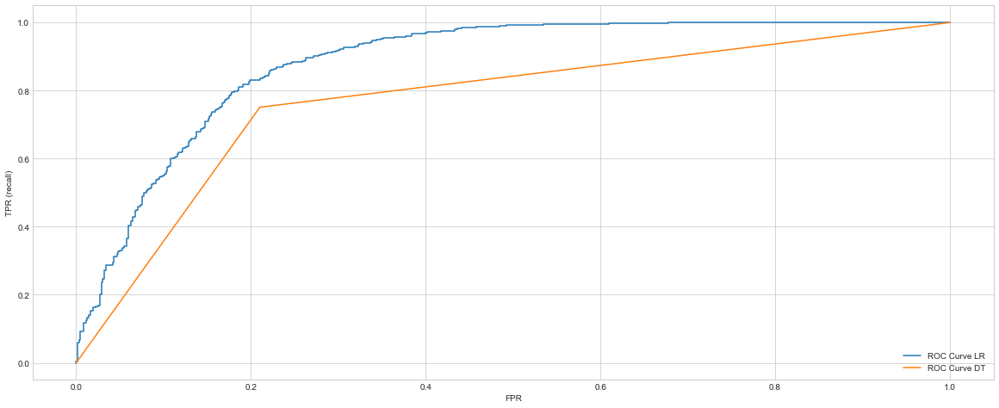

In [186]:
fpr_dt, tpr_dt, thresholds_dt = roc_curve(y_test, DT_classifier.predict_proba(X_test)[:, 1])
plt.plot(lr_fpr, lr_tpr, label="ROC Curve LR")
plt.plot(fpr_dt, tpr_dt, label="ROC Curve DT")
plt.xlabel("FPR")
plt.ylabel("TPR (recall)")
plt.legend(loc=4)

https://classeval.wordpress.com/introduction/introduction-to-the-roc-receiver-operating-characteristics-plot/ = to see if these straight lines are ok or not

In [187]:
dt_auc = roc_auc_score(y_test, DT_classifier.predict_proba(X_test)[:, 1])
print("AUC score for LR",lr_auc)
print("AUC score for DT",dt_auc)

AUC score for LR 0.8835201779552837
AUC score for DT 0.7704541145839916


Logistic Regression is better than Decision Trees at this point

## Random Forest

No formal distributional assumptions, random forests are non-parametric and can thus handle skewed and multi-modal data as well as categorical data that are ordinal or non-ordinal.

In [188]:
from sklearn.ensemble import RandomForestClassifier
RF_classifier = RandomForestClassifier(random_state=29) # with the default parameters

In [189]:
RF_classifier= RF_classifier.fit(X_train,y_train)

In [190]:
y_pred_RF = RF_classifier.predict(X_test)

In [192]:
print("Train Accuracy", round(RF_classifier.score(X_train,y_train),3))
print("Test Accuracy", round(RF_classifier.score(X_test,y_test),3))

Train Accuracy 0.999
Test Accuracy 0.859


In [193]:
ytrain_prob_RF = RF_classifier.predict_proba(X_train)
ytest_prob_RF = RF_classifier.predict_proba(X_test)

In [196]:
print("roc train score :",round(roc_auc_score(y_train,ytrain_prob_RF[:,1]),3))
print("roc test score :",round(roc_auc_score(y_test,ytest_prob_RF[:,1]),3))

roc train score : 1.0
roc test score : 0.931


https://towardsdatascience.com/one-common-misconception-about-random-forest-and-overfitting-47cae2e2c23b

In [197]:
print("Classification report\n\n",classification_report(y_test,y_pred_RF))
print('\nConfussion matrix:\n',confusion_matrix(y_test, y_pred_RF))

Classification report

               precision    recall  f1-score   support

           0       0.87      0.84      0.86       623
           1       0.85      0.87      0.86       635

    accuracy                           0.86      1258
   macro avg       0.86      0.86      0.86      1258
weighted avg       0.86      0.86      0.86      1258


Confussion matrix:
 [[526  97]
 [ 80 555]]


* The accuracy for Random Forest is 86%
* Out of 623 occurences of 0 class, model correctly predicted 526 of them and predicted 97 of them as class 1
* Out of 635 occurences of class 1 (hits), the model correctly predicted 555 of them and predicted 80 of them as flops (FN). 
* The model has the better recall for class 1 than for class 0.
* Precision (TP/(TP+FP)) is more for class 0 than for class 1. Precision is given more importance when you value FP more than FN.
* f1 score is the harmonic mean of precision and recall, and it is the same for class 1 and class 0

In [199]:
y_pred = RF_classifier.predict(X_test)
print("roc test score :",round(roc_auc_score(y_test,y_pred),2))

roc test score : 0.86


### ROC-AUC for Logistic Regression, Decision Trees, Random Forest

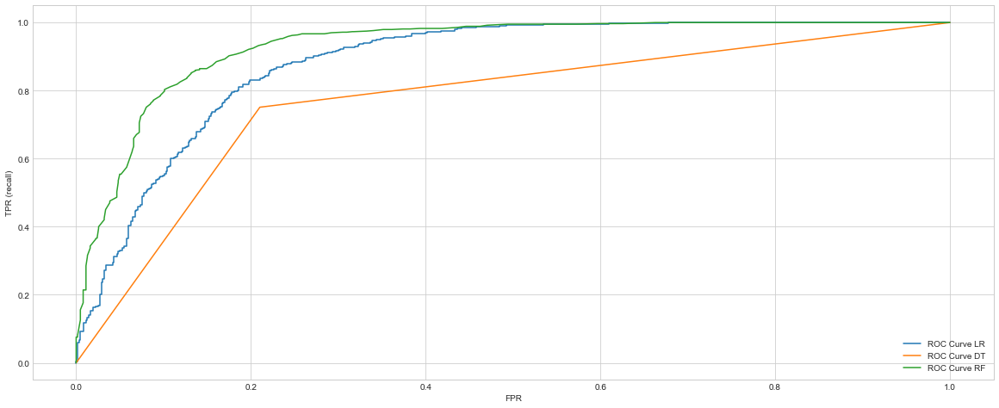

In [201]:
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, RF_classifier.predict_proba(X_test)[:, 1])

plt.plot(lr_fpr, lr_tpr, label="ROC Curve LR")
plt.plot(fpr_dt, tpr_dt, label="ROC Curve DT")
plt.plot(fpr_rf, tpr_rf, label="ROC Curve RF")

plt.xlabel("FPR")
plt.ylabel("TPR (recall)")

plt.legend(loc=4)

Random Forest has more area under the curve than both Logistic Regression and Decision Trees

In [202]:
rf_auc = roc_auc_score(y_test, RF_classifier.predict_proba(X_test)[:, 1])
print("AUC score for LR",lr_auc)
print("AUC score for DT",dt_auc)
print("AUC score for RF",rf_auc)

AUC score for LR 0.8835201779552837
AUC score for DT 0.7704541145839916
AUC score for RF 0.9309159388784267


Random Forest model is the one with the highest AUC score, and hence is better.

In [203]:
# current feature importance
feature_imp = pd.Series(RF_classifier.feature_importances_,index=X_feat.columns).sort_values(ascending=False)
feature_imp

instrumentalness    0.238341
loudness            0.107009
danceability        0.097391
acousticness        0.097337
energy              0.090351
duration_ms         0.068302
valence             0.062294
speechiness         0.050180
chorus_hit          0.041726
tempo               0.041365
liveness            0.040648
sections            0.027691
key                 0.024179
time_signature      0.006853
mode                0.006334
dtype: float64

Thus, __instrumentalness, loudness and danceability__ were the top 3 important features, while __key, time_signature and mode__ are the 3 least important predictors.

In [204]:
## Current parameters for Random Forest Classifier
RF_classifier.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'auto',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_impurity_split': None,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 29,
 'verbose': 0,
 'warm_start': False}

## SVM classifier

In [205]:
from sklearn.svm import SVC
# default model
SVM_classifier= SVC(probability=True,random_state=40)
# instantiate classifier with default hyperparameters with kernel=rbf, C=1.0 and gamma=auto

In [206]:
SVM_classifier= SVM_classifier.fit(X_train,y_train)

In [207]:
y_pred_SVM = SVM_classifier.predict(X_test)

In [208]:
print("Classification report\n\n",classification_report(y_test,y_pred_SVM))
print('\nConfussion matrix:\n',confusion_matrix(y_test, y_pred_SVM))

Classification report

               precision    recall  f1-score   support

           0       0.92      0.76      0.83       623
           1       0.80      0.93      0.86       635

    accuracy                           0.85      1258
   macro avg       0.86      0.85      0.85      1258
weighted avg       0.86      0.85      0.85      1258


Confussion matrix:
 [[476 147]
 [ 42 593]]


* The accuracy is 85%
* The recall is higher for class 1
* The precision is higher for class 0
* f1-score is higher for class 1

In [209]:
print("Train Accuracy", round(SVM_classifier.score(X_train,y_train),2))
print("Test Accuracy", round(SVM_classifier.score(X_test,y_test),2))

Train Accuracy 0.84
Test Accuracy 0.85


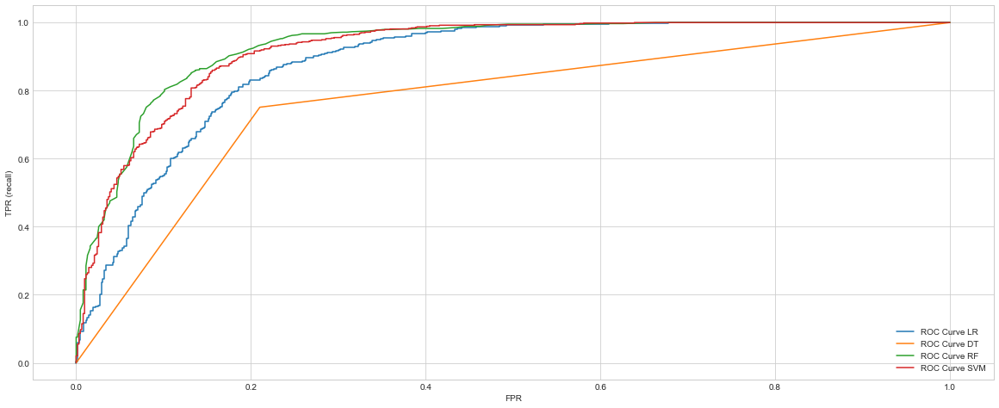

In [210]:
fpr_rf_SVM, tpr_rf_SVM, thresholds_rf_SVM = roc_curve(y_test, SVM_classifier.predict_proba(X_test)[:, 1])

plt.plot(lr_fpr, lr_tpr, label="ROC Curve LR")
plt.plot(fpr_dt, tpr_dt, label="ROC Curve DT")
plt.plot(fpr_rf, tpr_rf, label="ROC Curve RF")
#plt.plot(fpr_rf_random, tpr_rf_random, label="ROC Curve RF random cv")
#plt.plot(fpr_rf_grid, tpr_rf_grid, label="ROC Curve RF grid cv")
plt.plot(fpr_rf_SVM, tpr_rf_SVM, label="ROC Curve SVM")

plt.xlabel("FPR")
plt.ylabel("TPR (recall)")

plt.legend(loc=4)

In [211]:
rf_SVM_auc = roc_auc_score(y_test, SVM_classifier.predict_proba(X_test)[:, 1])
print("AUC score for LR: ",round(lr_auc,2))
print("AUC score for DT: ",round(dt_auc,2))
print("AUC score for RF: ",round(rf_auc,2))
#print("AUC score for RF random cv: ",round(rf_random_auc,3))
print("AUC score for SVM: ",round(rf_SVM_auc,2))

AUC score for LR:  0.88
AUC score for DT:  0.77
AUC score for RF:  0.93
AUC score for SVM:  0.92


Random Forest is the better model out of Logistic Regression, Decision Trees and Support Vector Machines

#### Hyperparamter tuning for the Random Forest Model

To see if the model can be improved

* Using Random Search CV

In [212]:
from sklearn.model_selection import RandomizedSearchCV
# Number of trees 
n_estimators = [int(x) for x in np.linspace(start = 150, stop = 2500, num = 10)]
# criterion
criterion = ['gini','entropy']
# Maximum number of levels in tree
max_depth = [int(x) for x in np.linspace(5, 100, num = 10)]
# Number of features to consider at every split
max_features = ['auto', 'log2']
# Minimum number of samples required at each leaf node
min_samples_leaf = [2,3, 4]

In [213]:
params = { 'n_estimators': n_estimators,
           'criterion': criterion,
           'max_depth': max_depth,
           'max_features': max_features,
           'min_samples_leaf': min_samples_leaf,
           }

In [214]:
RF_random_cv = RandomizedSearchCV(estimator = RF_classifier, 
                                  param_distributions = params, 
                                  cv = 5, verbose=2, random_state=36, n_jobs = -1)

In [215]:
# Fit the random search model
RF_random_cv.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(random_state=29),
                   n_jobs=-1,
                   param_distributions={'criterion': ['gini', 'entropy'],
                                        'max_depth': [5, 15, 26, 36, 47, 57, 68,
                                                      78, 89, 100],
                                        'max_features': ['auto', 'log2'],
                                        'min_samples_leaf': [2, 3, 4],
                                        'n_estimators': [150, 411, 672, 933,
                                                         1194, 1455, 1716, 1977,
                                                         2238, 2500]},
                   random_state=36, verbose=2)

In [216]:
RF_random_cv.best_params_

{'n_estimators': 933,
 'min_samples_leaf': 4,
 'max_features': 'log2',
 'max_depth': 47,
 'criterion': 'gini'}

In [217]:
RF_random_cv.best_estimator_

RandomForestClassifier(max_depth=47, max_features='log2', min_samples_leaf=4,
                       n_estimators=933, random_state=29)

In [218]:
## Fitting a model according to the best params found out by Random Search CV
RF_random_best =RandomForestClassifier(max_depth=47, max_features='log2', min_samples_leaf=4,
                       n_estimators=933, random_state=29)

In [219]:
RF_random_best.fit(X_train,y_train)

RandomForestClassifier(max_depth=47, max_features='log2', min_samples_leaf=4,
                       n_estimators=933, random_state=29)

In [220]:
y_pred_RF_random_best= RF_random_best.predict(X_test)

In [221]:
print("Classification report\n\n",classification_report(y_test,y_pred_RF_random_best))
print('\nConfussion matrix:\n',confusion_matrix(y_test, y_pred_RF_random_best))

Classification report

               precision    recall  f1-score   support

           0       0.88      0.82      0.85       623
           1       0.83      0.89      0.86       635

    accuracy                           0.85      1258
   macro avg       0.86      0.85      0.85      1258
weighted avg       0.86      0.85      0.85      1258


Confussion matrix:
 [[510 113]
 [ 70 565]]


In [222]:
ytrain_prob_RF_random = RF_random_best.predict_proba(X_train)
ytest_prob_RF_random = RF_random_best.predict_proba(X_test)

print("roc train score :",round(roc_auc_score(y_train,ytrain_prob_RF_random[:,1]),3))
print("roc test score :",round(roc_auc_score(y_test,ytest_prob_RF_random[:,1]),3))

roc train score : 0.993
roc test score : 0.93


In [223]:
print("Train Accuracy", round(RF_random_best.score(X_train,y_train),2))
print("Test Accuracy", round(RF_random_best.score(X_test,y_test),2))

Train Accuracy 0.94
Test Accuracy 0.85


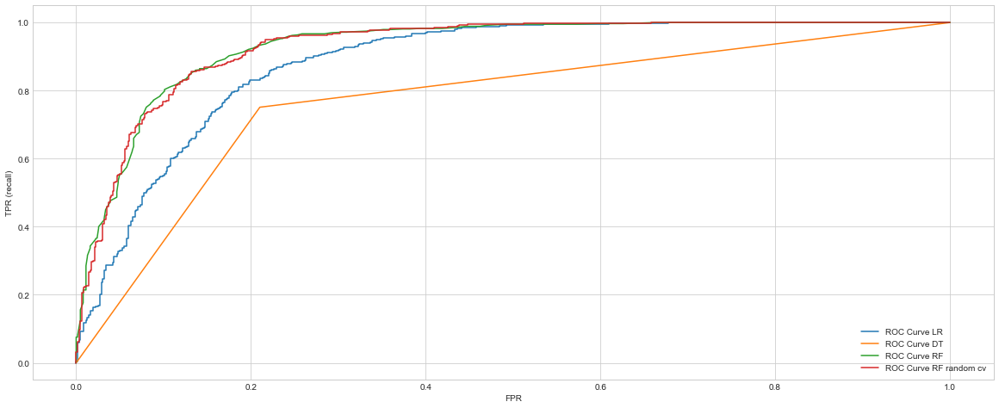

In [224]:
fpr_rf_random, tpr_rf_random, thresholds_rf_random = roc_curve(y_test, RF_random_best.predict_proba(X_test)[:, 1])

plt.plot(lr_fpr, lr_tpr, label="ROC Curve LR")
plt.plot(fpr_dt, tpr_dt, label="ROC Curve DT")
plt.plot(fpr_rf, tpr_rf, label="ROC Curve RF")
plt.plot(fpr_rf_random, tpr_rf_random, label="ROC Curve RF random cv")

plt.xlabel("FPR")
plt.ylabel("TPR (recall)")

plt.legend(loc=4)

In [225]:
rf_random_auc = roc_auc_score(y_test, RF_random_best.predict_proba(X_test)[:, 1])
print("AUC score for LR: ",round(lr_auc,3))
print("AUC score for DT: ",round(dt_auc,3))
print("AUC score for RF: ",round(rf_auc,3))
print("AUC score for RF random cv: ",round(rf_random_auc,3))

AUC score for LR:  0.884
AUC score for DT:  0.77
AUC score for RF:  0.931
AUC score for RF random cv:  0.93


The base random classifier model performs a bit better than the random forest classifier model that we got using random search CV

* Using Grid Search CV

In [226]:
from sklearn.model_selection import GridSearchCV
# Create the parameter grid based on the results of random search 
param_grid = {
    'max_depth': [60, 70 ,80, 90, 100],
    'min_samples_leaf': [2,4,5],
    'n_estimators': [250, 500, 1000, 1500,1700],
    'min_samples_split': [2,3,4]
}

# Instantiate the grid search model
grid_search = GridSearchCV(estimator = RF_classifier, param_grid = param_grid, 
                          cv = 5, n_jobs = -1, verbose = 2)

In [227]:
# Fit the grid search to the data
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 225 candidates, totalling 1125 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=29), n_jobs=-1,
             param_grid={'max_depth': [60, 70, 80, 90, 100],
                         'min_samples_leaf': [2, 4, 5],
                         'min_samples_split': [2, 3, 4],
                         'n_estimators': [250, 500, 1000, 1500, 1700]},
             verbose=2)

In [228]:
grid_search.best_params_

{'max_depth': 60,
 'min_samples_leaf': 4,
 'min_samples_split': 2,
 'n_estimators': 1000}

In [229]:
grid_search.best_estimator_ # add max_features = log2, criterion = "gini"

RandomForestClassifier(max_depth=60, min_samples_leaf=4, n_estimators=1000,
                       random_state=29)

In [230]:
RF_classifier_gridcv=RandomForestClassifier(max_depth=60, min_samples_leaf=4, n_estimators=1000,
                       random_state=29,max_features='log2')

In [231]:
RF_classifier_gridcv= RF_classifier_gridcv.fit(X_train,y_train)
y_pred_RF_gridcv=RF_classifier_gridcv.predict(X_test)

In [232]:
print("Classification report\n\n",classification_report(y_test,y_pred_RF_gridcv))
print('\nConfussion matrix:\n',confusion_matrix(y_test, y_pred_RF_gridcv))

Classification report

               precision    recall  f1-score   support

           0       0.88      0.82      0.85       623
           1       0.83      0.89      0.86       635

    accuracy                           0.85      1258
   macro avg       0.86      0.85      0.85      1258
weighted avg       0.86      0.85      0.85      1258


Confussion matrix:
 [[511 112]
 [ 71 564]]


In [233]:
print("Train Accuracy", round(RF_classifier_gridcv.score(X_train,y_train),2))
print("Test Accuracy", round(RF_classifier_gridcv.score(X_test,y_test),2))

Train Accuracy 0.94
Test Accuracy 0.85


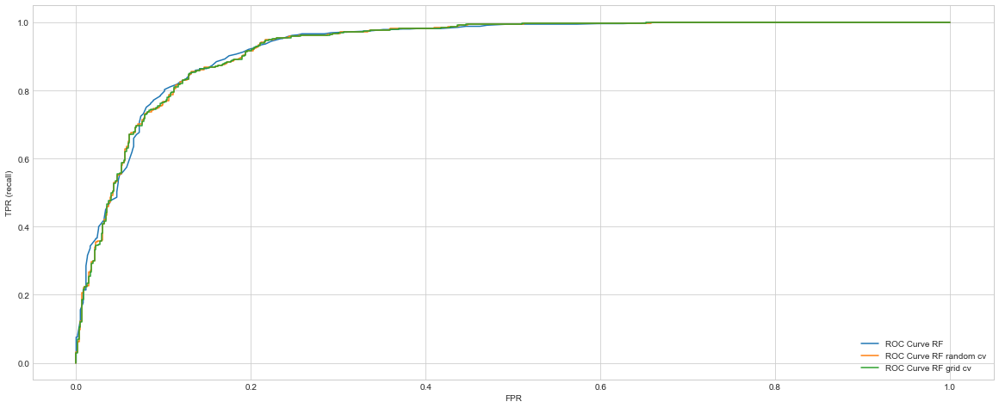

In [243]:
fpr_rf_grid, tpr_rf_grid, thresholds_rf_grid = roc_curve(y_test, RF_classifier_gridcv.predict_proba(X_test)[:, 1])

plt.plot(fpr_rf, tpr_rf, label="ROC Curve RF")
plt.plot(fpr_rf_random, tpr_rf_random, label="ROC Curve RF random cv")
plt.plot(fpr_rf_grid, tpr_rf_grid, label="ROC Curve RF grid cv")

plt.xlabel("FPR")
plt.ylabel("TPR (recall)")

plt.legend(loc=4)

In [242]:
rf_grid_auc = roc_auc_score(y_test, RF_classifier_gridcv.predict_proba(X_test)[:, 1])
print("AUC score for RF: ",round(rf_auc,3))
print("AUC score for RF random cv: ",round(rf_random_auc,3))
print("AUC score for RF grid cv: ",round(rf_grid_auc,3))

AUC score for RF:  0.931
AUC score for RF random cv:  0.93
AUC score for RF grid cv:  0.93


Thus, we get the same score the random search model and the grid search model fro Random Forest. <br>
The best model is thus the initial Random Forest Classifier with an AUC score of 93.1% and an accuracy of 86% ( a model that has a better recall for class 1)

__Thankyou__